# 04 — Predictive Analytics: Default Classification (`default_12m`)

## Tujuan
1. Memvalidasi pembagian data berbasis waktu (*temporal split*: Latih `<= 2018-06-30`, Validasi `2018-07-01` s.d. `2019-06-30`, Uji `>= 2019-07-01`) pada populasi pinjaman yang telah teramati penuh 12 bulan (`default_12m` valid, `n = 148.369`, `43.117` gagal bayar / `29,06%`), serta membandingkannya terhadap pembagian acak terstratifikasi `70/15/15`.
2. Mendefinisikan set fitur secara terprogram tanpa kebocoran data (*zero data leakage*): **Set A** (`36` fitur stabil setelah menyaring 8 fitur *mati-era*), **Set B** (`44` fitur kandidat lengkap `boleh_jadi_fitur == Y`), dan **Set C** (`39` fitur ablasi: `Set A` + `Rating`, `ProbabilityOfDefault`, `Interest`).
3. Mengevaluasi model klasifikasi (`LR-A`, `LGBM-A`, `LGBM-B`, `LGBM-C`, dan `LGBM-A-acak`) beserta kalibrasi probabilitas (*Platt/Sigmoid* vs *Isotonik* via 5-fold CV pada validasi) terhadap pembanding internal platform (`ProbabilityOfDefault` dan suku bunga `Interest`).
4. Menganalisis daya pisah per desil (*decile lift*), stabilitas kinerja lintas subgrup (`Country`, kelompok tenor `LoanDuration_group`, `NewCreditCustomer`, dan paruh waktu uji), serta interpretabilitas fitur (`SHAP`, *Permutation Importance*, koefisien `LR-A`, dan perbandingan `IV` hanya pada data latih vs Tahap 3).

## Input / Output
- **Input:**
  - Dataset bersih: `data/processed/bondora_clean.parquet` (`179.235 × 130`) & `data/processed/schema.json` (`44` kandidat fitur `Y`).
  - Artefak hasil pipeline satu perintah (`python -m src.models.train`): `models/lgbm_default12m_setA.joblib`, `models/lr_default12m_setA.joblib`, `models/train_metadata.json`, `data/processed/predictions_default12m.parquet`, tabel `reports/tables/04_*.csv`, dan grafik `reports/figures/04_*.png`.
- **Output:**
  - Pemeriksaan nilai antara (*intermediate values*), tabel evaluasi, visualisasi kurva ROC, kalibrasi, *lift* per desil, SHAP, subgrup, serta **Ringkasan Temuan Predictive & Implikasi untuk Tahap 5**.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import src.config as config

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 140)

with open(config.MODELS_DIR / "train_metadata.json", "r", encoding="utf-8") as f:
    train_meta = json.load(f)

print(f"Project root         : {config.PROJECT_ROOT}")
print(f"Random seed          : {config.RANDOM_SEED}")
print(f"REPORT_DATE          : {config.REPORT_DATE}")
print(f"Batas Latih / Val    : <= {config.SPLIT_TRAIN_END} | <= {config.SPLIT_VAL_END} | > {config.SPLIT_VAL_END}")
print(f"Waktu eksekusi train : {train_meta['total_elapsed_seconds']:.2f} detik (klasifikasi: {train_meta['classification']['elapsed_seconds']:.2f} dtk)")
print("Preflight terverifikasi:", train_meta["preflight"])

Project root         : C:\Tugas-3-Pemodelan-Data\bondora-analytics
Random seed          : 42
REPORT_DATE          : 2021-07-20
Batas Latih / Val    : <= 2018-06-30 | <= 2019-06-30 | > 2019-06-30
Waktu eksekusi train : 512.60 detik (klasifikasi: 436.66 dtk)
Preflight terverifikasi: {'n_rows': 179235, 'n_cols': 130, 'observable_12m': 148783, 'valid_default_12m': 148369, 'sum_default_12m': 43117, 'rate_default_12m_pct': 29.06, 'n_features_Y': 44, 'report_date': '2021-07-20'}


## 1. Pembagian Data Berbasis Waktu vs Acak Terstratifikasi (`04_split_summary.csv`)

Pada penggunaan dunia nyata, model risiko kredit dilatih menggunakan kohort historis dan diterapkan untuk menilai kohort masa depan. Oleh sebab itu, pembagian utama dilakukan berdasarkan tanggal pencairan (`LoanDate`):
- **Latih (`train`):** `LoanDate <= 2018-06-30` (`59.459` baris; `18.452` gagal bayar / `31,03%`)
- **Validasi (`val`):** `2018-07-01 <= LoanDate <= 2019-06-30` (`34.627` baris; `10.133` gagal bayar / `29,26%`) — digunakan untuk penyetelan hiperparameter, *early stopping*, pemilihan metode kalibrasi, dan penentuan ambang *Youden's J*.
- **Uji (`test`):** `LoanDate >= 2019-07-01` s.d. `2020-07-20` (`54.283` baris; `14.532` gagal bayar / `26,77%`) — dievaluasi satu kali di akhir.

> **Catatan Metodologis:** Pinjaman di akhir periode latih (`Juni 2018`) baru menyelesaikan pengamatan 12 bulan pada `Juni 2019` (beririsan dengan periode pencairan validasi), sedangkan seluruh pinjaman latih telah selesai diamati sebelum periode uji (`>= Juli 2019`) dimulai.

In [2]:
split_cls_df = pd.read_csv(config.TABLES_DIR / "04_split_summary.csv")
display(split_cls_df)

# Verifikasi nilai antara (pembilang, penyebut, proporsi)
temp_rows = split_cls_df.loc[split_cls_df["skema_split"] == "temporal"].set_index("split")
assert int(temp_rows.loc[["train", "val", "test"], "n"].sum()) == 148_369
assert int(temp_rows.loc[["train", "val", "test"], "n_default"].sum()) == 43_117
for sp in ["train", "val", "test"]:
    n_sp = int(temp_rows.loc[sp, "n"])
    d_sp = int(temp_rows.loc[sp, "n_default"])
    r_sp = float(temp_rows.loc[sp, "default_rate"])
    print(f"Split {sp:5s}: n = {n_sp:6,d} | n_default = {d_sp:6,d} | n_non_default = {n_sp - d_sp:6,d} | default_rate = {d_sp}/{n_sp} = {r_sp:.4%}")

,skema_split,split,deskripsi,n,proporsi_populasi,n_default,n_non_default,default_rate,loan_date_min,loan_date_max
0,temporal,train,Latih (<= 2018-06-30),59459,0.400751,18452,41007,0.310331,2009-02-28,2018-06-30
1,temporal,val,Validasi (> 2018-06-30 s.d. 2019-06-30),34627,0.233384,10133,24494,0.292633,2018-07-01,2019-06-30
2,temporal,test,Uji (> 2019-06-30),54283,0.365865,14532,39751,0.267708,2019-07-01,2020-07-20
3,temporal,Total,Seluruh Populasi Valid default_12m,148369,1.000000,43117,105252,0.290607,2009-02-28,2020-07-20
4,random_70_15_15,train,Acak Terstratifikasi Latih (70%),103858,0.699998,30182,73676,0.290608,2009-02-28,2020-07-20
5,random_70_15_15,val,Acak Terstratifikasi Validasi (15%),22255,0.149998,6467,15788,0.290586,2009-03-08,2020-07-20
6,random_70_15_15,test,Acak Terstratifikasi Uji (15%),22256,0.150004,6468,15788,0.290618,2009-03-01,2020-07-20


Split train: n = 59,459 | n_default = 18,452 | n_non_default = 41,007 | default_rate = 18452/59459 = 31.0331%
Split val  : n = 34,627 | n_default = 10,133 | n_non_default = 24,494 | default_rate = 10133/34627 = 29.2633%
Split test : n = 54,283 | n_default = 14,532 | n_non_default = 39,751 | default_rate = 14532/54283 = 26.7708%


## 2. Definisi Set Fitur & Deteksi Fitur Mati-Era (`04_feature_sets.csv`)

Dari `44` kolom kandidat (`boleh_jadi_fitur == 'Y'` pada `schema.json`), aturan deteksi fitur **mati-era** dihitung langsung dari data latih dan validasi:
- Suatu fitur dinyatakan **mati-era** apabila pada periode validasi proporsi nilai tunggal dominannya (termasuk `-1 (Not set)`, `0`, atau `NaN`) mencapai `>= 95%`, sementara pada periode latih proporsi nilai tersebut `<= 80%`.
- Hasilnya menyaring **8 fitur mati-era** (`UseOfLoan`, `MaritalStatus`, `EmploymentStatus`, `OccupationArea`, `IncomeFromPrincipalEmployer`, `DebtToIncome`, `FreeCash`, dan `CreditScoreEsMicroL`), sehingga diperoleh:
  - **Set A (Stabil, Utama):** `36` fitur
  - **Set B (Lengkap):** `44` fitur
  - **Set C (Ablasi Benchmark):** `39` fitur (`Set A` + `Rating`, `ProbabilityOfDefault`, `Interest`)

In [3]:
fsets_df = pd.read_csv(config.TABLES_DIR / "04_feature_sets.csv")
print(f"Jumlah fitur Set A (stabil) : {int(fsets_df['di_set_A'].sum())}")
print(f"Jumlah fitur Set B (lengkap): {int(fsets_df['di_set_B'].sum())}")
print(f"Jumlah fitur Set C (ablasi) : {int(fsets_df['di_set_C'].sum())}")

era_dead_tbl = fsets_df.loc[fsets_df["di_set_B"] & (~fsets_df["di_set_A"]), [
    "fitur", "tipe", "nilai_dominan_validasi", "share_dominan_latih", "share_dominan_validasi", "psi_2018_2020", "alasan_keluar"
]].reset_index(drop=True)
print("\n=== 8 Fitur Mati-Era yang Dikeluarkan dari Set A ===")
display(era_dead_tbl)

print("\n=== Tabel Lengkap Keanggotaan Set Fitur (47 Kolom: 44 Kandidat + 3 Kolom Ablasi Set C) ===")
display(fsets_df)

Jumlah fitur Set A (stabil) : 36
Jumlah fitur Set B (lengkap): 44
Jumlah fitur Set C (ablasi) : 39

=== 8 Fitur Mati-Era yang Dikeluarkan dari Set A ===


,fitur,tipe,nilai_dominan_validasi,share_dominan_latih,share_dominan_validasi,psi_2018_2020,alasan_keluar
0,UseOfLoan,kategorikal,-1,0.384769,1.000000,16.5261,Mati-era: nilai dominan '-1 (Not set)' mencapa...
1,MaritalStatus,kategorikal,-1,0.384769,1.000000,17.0376,Mati-era: nilai dominan '-1 (Not set)' mencapa...
2,EmploymentStatus,kategorikal,-1,0.384769,1.000000,17.6851,Mati-era: nilai dominan '-1 (Not set)' mencapa...
3,OccupationArea,kategorikal,-1,0.385627,1.000000,12.9986,Mati-era: nilai dominan '-1 (Not set)' mencapa...
4,IncomeFromPrincipalEmployer,numerik,0.0,0.423754,1.000000,8.2825,Mati-era: nilai dominan '0.0' mencapai 100.00%...
5,DebtToIncome,numerik,0.0,0.422291,1.000000,8.2750,Mati-era: nilai dominan '0.0' mencapai 100.00%...
6,FreeCash,numerik,0.0,0.422241,1.000000,8.2775,Mati-era: nilai dominan '0.0' mencapai 100.00%...
7,CreditScoreEsMicroL,kategorikal,M,0.306009,0.976261,16.6926,Mati-era: nilai dominan 'M' mencapai 97.63% di...



=== Tabel Lengkap Keanggotaan Set Fitur (47 Kolom: 44 Kandidat + 3 Kolom Ablasi Set C) ===


,fitur,tipe,di_set_A,di_set_B,di_set_C,alasan_keluar,nilai_dominan_validasi,share_dominan_latih,share_dominan_validasi,psi_2018_2020
0,NewCreditCustomer,boolean,True,True,True,Aktif & stabil (masuk Set A),True,0.571049,0.515840,0.1070
1,ApplicationSignedHour,numerik,True,True,True,Aktif & stabil (masuk Set A),11,0.079685,0.079707,0.0852
2,ApplicationSignedWeekday,numerik,True,True,True,Aktif & stabil (masuk Set A),3,0.185590,0.180379,0.0373
3,VerificationType,kategorikal,True,True,True,Aktif & stabil (masuk Set A),4,0.477321,0.507610,2.3104
4,LanguageCode,kategorikal,True,True,True,Aktif & stabil (masuk Set A),1,0.525000,0.512721,0.1279
5,Age,numerik,True,True,True,Aktif & stabil (masuk Set A),34,0.030963,0.029024,0.1042
6,Country,kategorikal,True,True,True,Aktif & stabil (masuk Set A),EE,0.620814,0.617120,0.0865
7,AppliedAmount,numerik,True,True,True,Aktif & stabil (masuk Set A),530.0,0.192065,0.204840,0.9421
8,Amount,numerik,True,True,True,Aktif & stabil (masuk Set A),530.0,0.191207,0.204811,0.7986
9,LoanDuration,numerik,True,True,True,Aktif & stabil (masuk Set A),60,0.380851,0.547896,0.5946


## 3. Evaluasi Model Klasifikasi, Pembanding Platform, & Kalibrasi Probabilitas (`04_metrics_classification.csv`, `04_auc_comparisons.csv`)

Berikut adalah perbandingan menyeluruh pada data validasi (`n = 34.627`) dan data uji (`n = 54.283`):
- **Penanganan Kelas (`29,06%` positif):** Pencarian hiperparameter membandingkan model standar (`scale_pos_weight=1`) terhadap `is_unbalance=True` pada data validasi. Konfigurasi standar unggul baik pada ROC-AUC validasi (`0,7450` vs `0,7348`) maupun Brier score (`0,1789` vs `0,1944`), karena pembobotan kelas menggeser probabilitas prediksi menjauhi proporsi aktual.
- **Kalibrasi Probabilitas:** Perbandingan validasi silang 5-lipat (*5-fold CV*) pada data validasi menunjukkan **kalibrasi Isotonik** menghasilkan Brier CV lebih rendah (`0,1753`) dibanding *Platt/Sigmoid* (`0,1757`) dan skor mentah (`0,1789`). Pada data uji, kalibrasi memperbaiki Brier `LGBM-A` dari `0,1926` menjadi **`0,1798`** dan menurunkan *Expected Calibration Error* (ECE 10-bin) separuhnya dari `0,1236` menjadi **`0,0619`**.
- **Catatan Cakupan Metrik (in-sample vs out-of-sample):** Seluruh metrik pada baris `val`/`val_random` — termasuk Brier, ECE (`0,0000` pada model terkalibrasi), rata-rata prediksi = aktual (`29,26%`), dan ambang *Youden* — bersifat **in-sample**, karena hiperparameter, *early stopping*, kalibrator isotonik, dan ambang dipelajari dari data validasi yang sama. **Hanya metrik pada baris `test*` (out-of-sample) yang dipakai untuk pelaporan.** Kolom `cakupan_evaluasi` pada `04_metrics_classification.csv` menandai hal ini per baris.

=== Ringkasan Penyetelan & Kalibrasi Validasi (dari train_metadata.json) ===
Perbandingan is_unbalance pada validasi: {'val_auc_standard': 0.744956, 'val_auc_is_unbalance_true': 0.734808, 'val_brier_standard': 0.178855, 'val_brier_is_unbalance_true': 0.194382}
Perbandingan kalibrasi 5-fold CV pada validasi: {'brier_val_raw': 0.17885472949966075, 'brier_val_cv5_sigmoid': 0.1757085722185979, 'brier_val_cv5_isotonic': 0.17528024684304908}
Metode kalibrasi terpilih: isotonic

=== Tabel Metrik Klasifikasi (Validasi & Uji) ===


,kode_model,nama_model,set_fitur,split,n,n_default,default_rate,roc_auc,auc_ci_low_95,auc_ci_high_95,pr_auc,gini,ks,brier_score,log_loss,ece_10bin,threshold_youden_val,tn,fp,fn,tp,precision_youden,recall_youden,f1_youden,precision_top10pct,recall_top10pct,precision_top20pct,recall_top20pct,precision_top30pct,recall_top30pct,cakupan_evaluasi
0,LR-A,Logistic Regression (Terkalibrasi),Set A (36 fitur),val,34627,10133,0.292633,0.731200,NaN,NaN,0.505595,0.462400,0.358184,0.178059,0.533111,0.000000,0.308376,16934.0,7560.0,3376.0,6757.0,0.471956,0.666831,0.552720,0.597748,0.204283,0.558267,0.381526,0.518483,0.531531,validasi (in-sample): penyetelan hiperparamete...
1,LGBM-A-raw,LightGBM Utama (Sebelum Kalibrasi),Set A (36 fitur),val,34627,10133,0.292633,0.744956,NaN,NaN,0.524885,0.489911,0.370611,0.178855,0.535821,0.057901,0.331044,17016.0,7478.0,3284.0,6849.0,0.478048,0.675910,0.560016,0.607566,0.207638,0.569964,0.389519,0.531671,0.545051,validasi (in-sample): penyetelan hiperparamete...
2,LGBM-A,LightGBM Utama (Terkalibrasi),Set A (36 fitur),val,34627,10133,0.292633,0.746001,NaN,NaN,0.520797,0.492002,0.370611,0.174589,0.522785,0.000000,0.293930,17016.0,7478.0,3284.0,6849.0,0.478048,0.675910,0.560016,0.621427,0.212375,0.570830,0.390112,0.532826,0.546235,validasi (in-sample): penyetelan hiperparamete...
3,LGBM-B,LightGBM Lengkap (Terkalibrasi),Set B (44 fitur),val,34627,10133,0.292633,0.747326,NaN,NaN,0.522311,0.494651,0.373156,0.174082,0.521578,0.000000,0.320000,17395.0,7099.0,3415.0,6718.0,0.486213,0.662982,0.561002,0.618250,0.211290,0.577184,0.394454,0.534848,0.548308,validasi (in-sample): penyetelan hiperparamete...
4,LGBM-C,LightGBM Ablasi + Rating/PD/Interest,Set C (39 fitur),val,34627,10133,0.292633,0.746977,NaN,NaN,0.522720,0.493954,0.375118,0.174742,0.523447,0.009762,0.254012,15809.0,8685.0,2739.0,7394.0,0.459854,0.729695,0.564169,0.610453,0.208625,0.570108,0.389618,0.532056,0.545446,validasi (in-sample): penyetelan hiperparamete...
5,LGBM-A-acak,LightGBM Split Acak 70/15/15,Set A (36 fitur),val_random,22255,6467,0.290586,0.792610,NaN,NaN,0.608675,0.585221,0.444444,0.159374,0.484699,0.006432,0.303093,11609.0,4179.0,1881.0,4586.0,0.523217,0.709139,0.602153,0.714286,0.245864,0.645024,0.443946,0.576992,0.595639,validasi (in-sample): penyetelan hiperparamete...
6,LR-A-raw,Logistic Regression (Sebelum Kalibrasi),Set A (36 fitur),test,54283,14532,0.267708,0.696445,0.691635,0.701166,0.402221,0.392890,0.318871,0.199956,0.581196,0.130552,0.352005,21949.0,17802.0,3396.0,11136.0,0.384823,0.766309,0.512353,0.434783,0.162400,0.433177,0.323631,0.422413,0.473369,uji (out-of-sample): metrik yang dipakai untuk...
7,LR-A,Logistic Regression (Terkalibrasi),Set A (36 fitur),test,54283,14532,0.267708,0.696369,0.691563,0.701077,0.400181,0.392739,0.318540,0.181905,0.540914,0.054212,0.308376,21949.0,17802.0,3396.0,11136.0,0.384823,0.766309,0.512353,0.450074,0.168112,0.436216,0.325901,0.423703,0.474814,uji (out-of-sample): metrik yang dipakai untuk...
8,LGBM-A-raw,LightGBM Utama (Sebelum Kalibrasi),Set A (36 fitur),test,54283,14532,0.267708,0.715445,0.711028,0.719901,0.446755,0.430890,0.324002,0.192578,0.565066,0.123584,0.331044,22603.0,17148.0,3576.0,10956.0,0.389838,0.753922,0.513932,0.537399,0.200729,0.481164,0.359483,0.440344,0.493463,uji (out-of-sample): metrik yang dipakai untuk...
9,LGBM-A-sigmoid,LightGBM Utama (Kalibrasi Platt/Sigmoid),Set A (36 fitur),test,54283,14532,0.267708,0.715445,0.711028,0.719901,0.446755,0.430890,0.324002,0.180896,0.537011,0.063561,0.263870,22603.0,17148.0,3576.0,10956.0,0.389838,0.753922,0.513932,0.537399,0.200729,0.481164,0.359483,0.440344,0.493463,uji (out-of-sample): metrik yang dipakai untuk...



=== Uji Selisih ROC-AUC Berpasangan (Paired Bootstrap 200 Iterasi pada Data Uji) ===


,perbandingan,populasi_uji,n,auc_a,auc_b,diff_auc,ci_low_95,ci_high_95
0,LGBM-A (Set A) vs LGBM-B (Set B Lengkap),Seluruh Uji (n = 54.283),54283,0.715155,0.720580,-0.005425,-0.006314,-0.004575
1,LGBM-C (Set A + Rating/PD/Interest) vs LGBM-A ...,Seluruh Uji (n = 54.283),54283,0.707782,0.715155,-0.007373,-0.009263,-0.005516
2,LGBM-A (Set A) vs LR-A (Logistic Regression Se...,Seluruh Uji (n = 54.283),54283,0.715155,0.696369,0.018786,0.017197,0.020407
3,LGBM-A (Set A) vs ProbabilityOfDefault Bondora,Irisan Benchmark Uji (n = 54283),54283,0.715155,0.674584,0.040571,0.034319,0.046109
4,LGBM-A (Set A) vs Suku Bunga Interest,Irisan Benchmark Uji (n = 54283),54283,0.715155,0.685095,0.030060,0.024863,0.033385


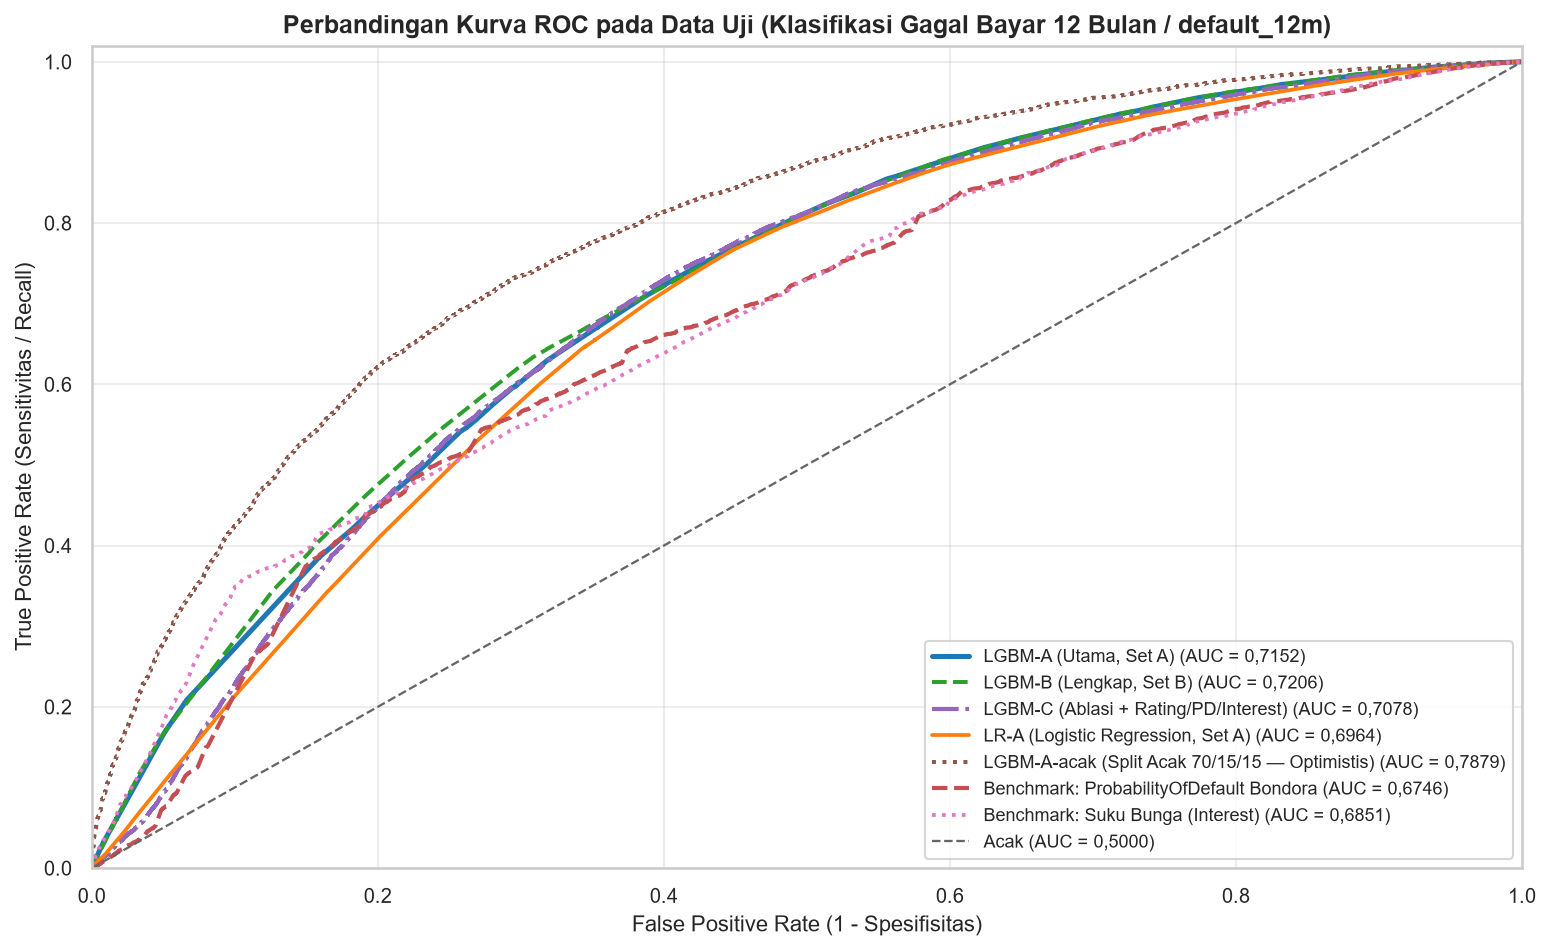

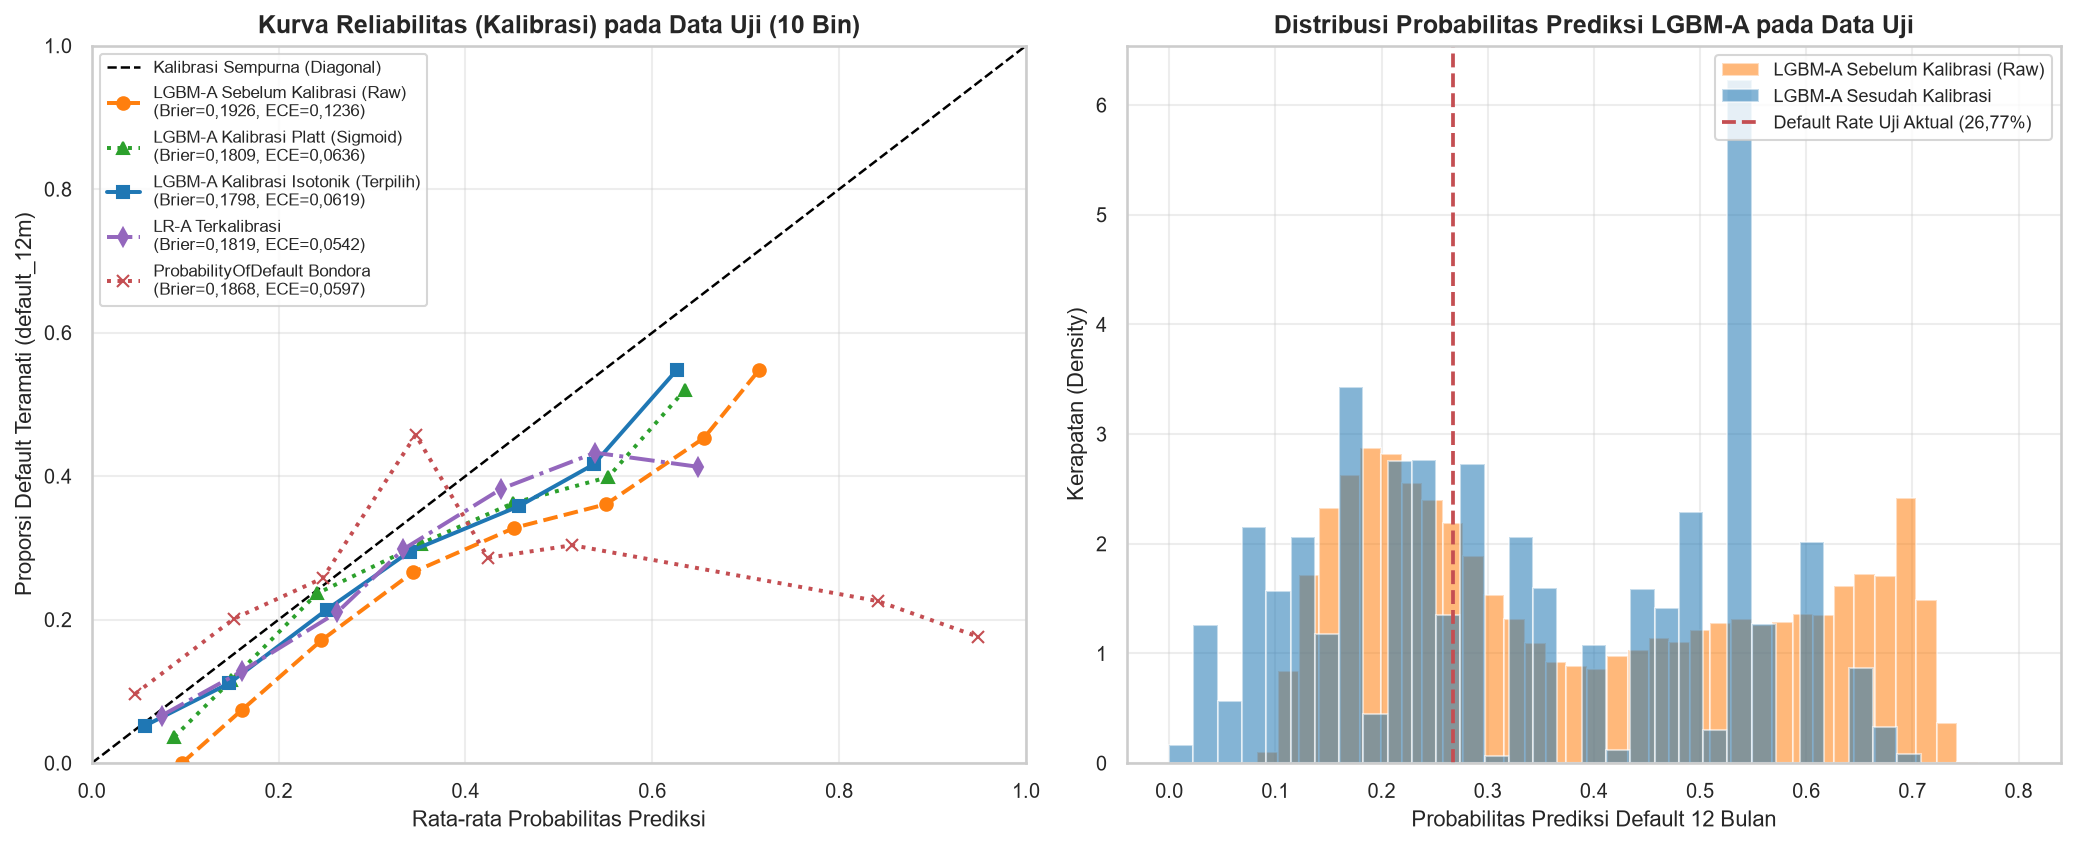

In [4]:
metrics_cls_df = pd.read_csv(config.TABLES_DIR / "04_metrics_classification.csv")
auc_comp_df = pd.read_csv(config.TABLES_DIR / "04_auc_comparisons.csv")

print("=== Ringkasan Penyetelan & Kalibrasi Validasi (dari train_metadata.json) ===")
print("Perbandingan is_unbalance pada validasi:", train_meta["classification"]["lgbm_a_unbalance_comparison"])
print("Perbandingan kalibrasi 5-fold CV pada validasi:", train_meta["classification"]["lgbm_a_calibration_cv"])
print("Metode kalibrasi terpilih:", train_meta["classification"]["lgbm_a_selected_calibration"])

print("\n=== Tabel Metrik Klasifikasi (Validasi & Uji) ===")
display(metrics_cls_df)

print("\n=== Uji Selisih ROC-AUC Berpasangan (Paired Bootstrap 200 Iterasi pada Data Uji) ===")
display(auc_comp_df)

display(Image(filename=str(config.FIGURES_DIR / "04_roc_curves.png")))
display(Image(filename=str(config.FIGURES_DIR / "04_calibration_curve.png")))

## 4. Daya Pisah per Desil Risiko (*Decile Lift*) & Kinerja per Subgrup (`04_lift_by_decile.csv`, `04_subgroup_performance.csv`)

Tabel *lift* membagi `54.283` pinjaman uji menjadi 10 desil dari risiko prediksi tertinggi (**Desil 1**) hingga terendah (**Desil 10**):
- **Desil 1 (`n = 5.429`):** memiliki tingkat gagal bayar aktual **`53,80%`** (`2.921` default), atau **lift `2,01x`** dibanding rata-rata populasi uji (`26,77%`), dan menangkap **`20,10%`** dari seluruh kejadian gagal bayar.
- **3 Desil Teratas (Top 30%, `n = 16.287`):** menangkap **`49,44%`** (`7.185` dari `14.532`) kejadian gagal bayar pada data uji.
- **Desil 10 (`n = 5.428`):** memiliki tingkat gagal bayar aktual hanya **`5,18%`** (`281` default; lift `0,19x`), menghasilkan rasio tingkat gagal bayar Desil 1 terhadap Desil 10 sebesar **`10,39x`**.
- **Evaluasi Subgrup & Pembanding Dalam-Negara (`04_subgroup_performance.csv`):** Pada baris uji yang sama, ROC-AUC dalam-negara `LGBM-A` vs `ProbabilityOfDefault` Bondora (PD) vs `Interest` (selisih = `LGBM-A` dikurangi pembanding; CI 95% *paired bootstrap* 200 iterasi):
  - **`EE`** (`n = 27.976`): `0,6799` vs PD `0,6295` vs `Interest` `0,6034`; selisih vs PD **`+0,0504`** `[+0,0397, +0,0608]`, vs `Interest` **`+0,0765`** `[+0,0658, +0,0859]`.
  - **`FI`** (`n = 13.645`): `0,5496` vs PD `0,5560` vs `Interest` `0,5051`; selisih vs PD **`-0,0063`** `[-0,0211, +0,0090]` — **CI mencakup 0, keunggulan atas PD tidak terbukti di Finlandia**; vs `Interest` **`+0,0446`** `[+0,0291, +0,0617]`.
  - **`ES`** (`n = 12.662`): `0,5831` vs PD `0,5556` vs `Interest` `0,5522`; selisih vs PD **`+0,0275`** `[+0,0169, +0,0395]`, vs `Interest` **`+0,0309`** `[+0,0202, +0,0431]`.
  - Keunggulan agregat `+0,0406` atas PD karena itu **tidak merata**: terbukti di `EE` dan `ES`, tidak terbukti di `FI`. Seluruh AUC dalam-negara (`0,55–0,68`) juga lebih rendah daripada AUC gabungan (`0,7152`): sebagian daya pisah gabungan berasal dari perbedaan tingkat risiko antar-negara (`EE` default `15,16%` vs `ES` `53,27%`), bukan dari pemeringkatan di dalam satu negara. *(Slovakia `SK` memiliki `n = 0` pada periode uji `>= Juli 2019`.)*

=== Tabel Lift & Cumulative Gain 10 Desil pada Data Uji (LGBM-A Terkalibrasi) ===


,desil,n,n_default,observed_default_rate,mean_predicted_prob,min_predicted_prob,max_predicted_prob,lift_desil,cum_n,cum_default,cum_default_rate,cum_recall_captured,cum_lift
0,1,5429,2921,0.538036,0.609353,0.551724,0.800000,2.0098,5429,2921,0.538036,0.201005,2.0098
1,2,5429,2293,0.422361,0.536530,0.535852,0.551724,1.5777,10858,5214,0.480199,0.358794,1.7937
2,3,5429,1971,0.363050,0.509930,0.485952,0.535852,1.3561,16287,7185,0.441149,0.494426,1.6479
3,4,5428,1933,0.356116,0.444265,0.404145,0.485952,1.3302,21715,9118,0.419894,0.627443,1.5685
4,5,5428,1601,0.294952,0.335391,0.293930,0.404145,1.1018,27143,10719,0.394908,0.737614,1.4751
5,6,5428,1295,0.238578,0.275440,0.239340,0.293930,0.8912,32571,12014,0.368856,0.826727,1.3778
6,7,5428,1010,0.186072,0.225586,0.206573,0.239340,0.6951,37999,13024,0.342746,0.896229,1.2803
7,8,5428,717,0.132093,0.176656,0.151351,0.206573,0.4934,43427,13741,0.316416,0.945568,1.1819
8,9,5428,510,0.093957,0.123280,0.102776,0.151351,0.3510,48855,14251,0.291700,0.980663,1.0896
9,10,5428,281,0.051769,0.059350,0.000000,0.102776,0.1934,54283,14532,0.267708,1.000000,1.0000



=== Kinerja Model Utama LGBM-A per Subgrup pada Data Uji ===


,dimensi,subgrup,kode_model,n,n_default,observed_default_rate,mean_pred_prob_raw,mean_pred_prob_calibrated,selisih_pred_cal_minus_obs,roc_auc,auc_ci_low_95,auc_ci_high_95,pr_auc,ks,brier_score,selisih_auc_lgbm_a_minus_pembanding,selisih_auc_ci_low_95,selisih_auc_ci_high_95
0,Country,EE,LGBM-A,27976,4241,0.151594,0.226119,0.177397,0.025803,0.679887,0.671184,0.686799,0.255853,0.265579,0.122830,NaN,NaN,NaN
1,Country,EE,BASE-PD-Bondora,27976,4241,0.151594,NaN,NaN,NaN,0.629498,0.620222,0.637056,0.226697,0.192329,0.130732,0.050389,0.039716,0.060812
2,Country,EE,BASE-Interest,27976,4241,0.151594,NaN,NaN,NaN,0.603385,0.595009,0.610431,0.196381,0.164815,NaN,0.076502,0.065838,0.085949
3,Country,FI,LGBM-A,13645,3546,0.259875,0.538628,0.468171,0.208295,0.549642,0.538365,0.562307,0.288741,0.077876,0.237498,NaN,NaN,NaN
4,Country,FI,BASE-PD-Bondora,13645,3546,0.259875,NaN,NaN,NaN,0.555972,0.546206,0.563944,0.295141,0.089329,0.196347,-0.006330,-0.021067,0.009022
5,Country,FI,BASE-Interest,13645,3546,0.259875,NaN,NaN,NaN,0.505082,0.493095,0.516424,0.268782,0.046190,NaN,0.044560,0.029089,0.061728
6,Country,ES,LGBM-A,12662,6745,0.532696,0.597461,0.516514,-0.016182,0.583106,0.572494,0.592011,0.593072,0.109526,0.243622,NaN,NaN,NaN
7,Country,ES,BASE-PD-Bondora,12662,6745,0.532696,NaN,NaN,NaN,0.555614,0.545947,0.565888,0.568826,0.091493,0.300256,0.027492,0.016933,0.039459
8,Country,ES,BASE-Interest,12662,6745,0.532696,NaN,NaN,NaN,0.552205,0.541887,0.561456,0.570674,0.086341,NaN,0.030900,0.020211,0.043063
9,LoanDuration_group,<= 12 bulan,LGBM-A,1067,63,0.059044,0.243679,0.179080,0.120036,0.762166,0.718984,0.813233,0.151947,0.424066,0.079254,NaN,NaN,NaN



=== Pembanding Dalam-Negara pada Baris Uji yang Sama: LGBM-A vs PD Bondora vs Interest ===


,subgrup,kode_model,n,roc_auc,auc_ci_low_95,auc_ci_high_95,selisih_auc_lgbm_a_minus_pembanding,selisih_auc_ci_low_95,selisih_auc_ci_high_95
0,EE,LGBM-A,27976,0.679887,0.671184,0.686799,NaN,NaN,NaN
1,EE,BASE-PD-Bondora,27976,0.629498,0.620222,0.637056,0.050389,0.039716,0.060812
2,EE,BASE-Interest,27976,0.603385,0.595009,0.610431,0.076502,0.065838,0.085949
3,FI,LGBM-A,13645,0.549642,0.538365,0.562307,NaN,NaN,NaN
4,FI,BASE-PD-Bondora,13645,0.555972,0.546206,0.563944,-0.006330,-0.021067,0.009022
5,FI,BASE-Interest,13645,0.505082,0.493095,0.516424,0.044560,0.029089,0.061728
6,ES,LGBM-A,12662,0.583106,0.572494,0.592011,NaN,NaN,NaN
7,ES,BASE-PD-Bondora,12662,0.555614,0.545947,0.565888,0.027492,0.016933,0.039459
8,ES,BASE-Interest,12662,0.552205,0.541887,0.561456,0.030900,0.020211,0.043063


EE LGBM-A vs BASE-PD-Bondora : selisih +0.0504 [+0.0397, +0.0608] -> berbeda nyata: ya
EE LGBM-A vs BASE-Interest   : selisih +0.0765 [+0.0658, +0.0859] -> berbeda nyata: ya
FI LGBM-A vs BASE-PD-Bondora : selisih -0.0063 [-0.0211, +0.0090] -> berbeda nyata: TIDAK (CI mencakup 0)
FI LGBM-A vs BASE-Interest   : selisih +0.0446 [+0.0291, +0.0617] -> berbeda nyata: ya
ES LGBM-A vs BASE-PD-Bondora : selisih +0.0275 [+0.0169, +0.0395] -> berbeda nyata: ya
ES LGBM-A vs BASE-Interest   : selisih +0.0309 [+0.0202, +0.0431] -> berbeda nyata: ya


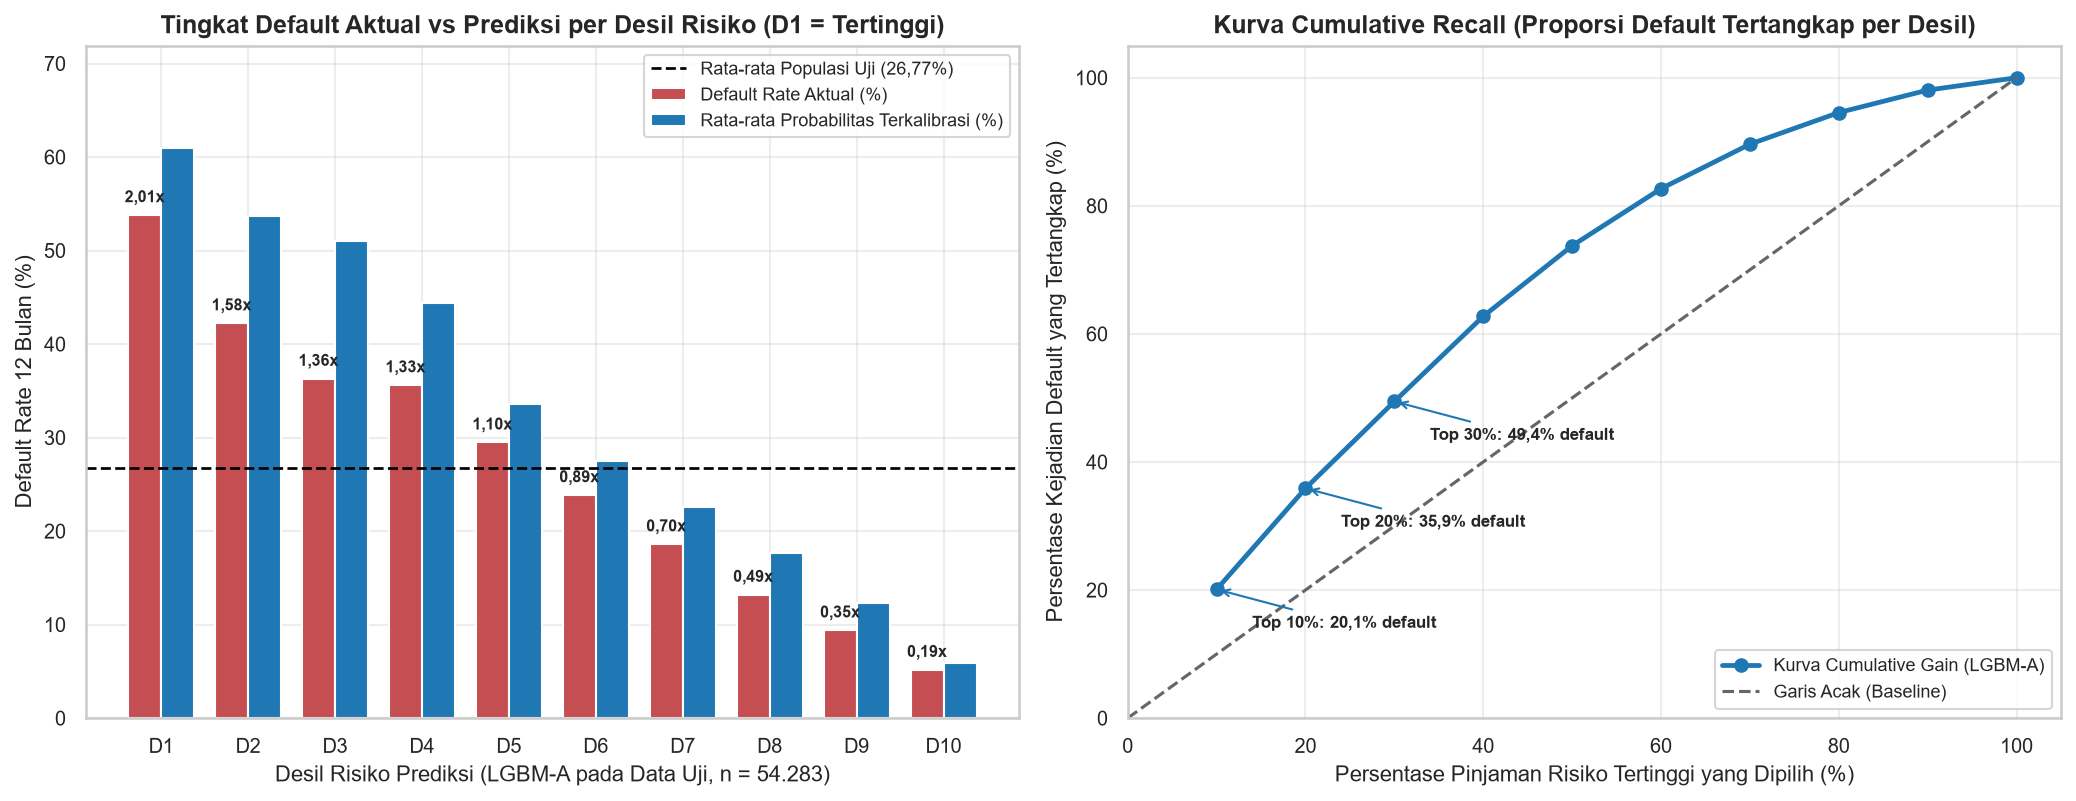

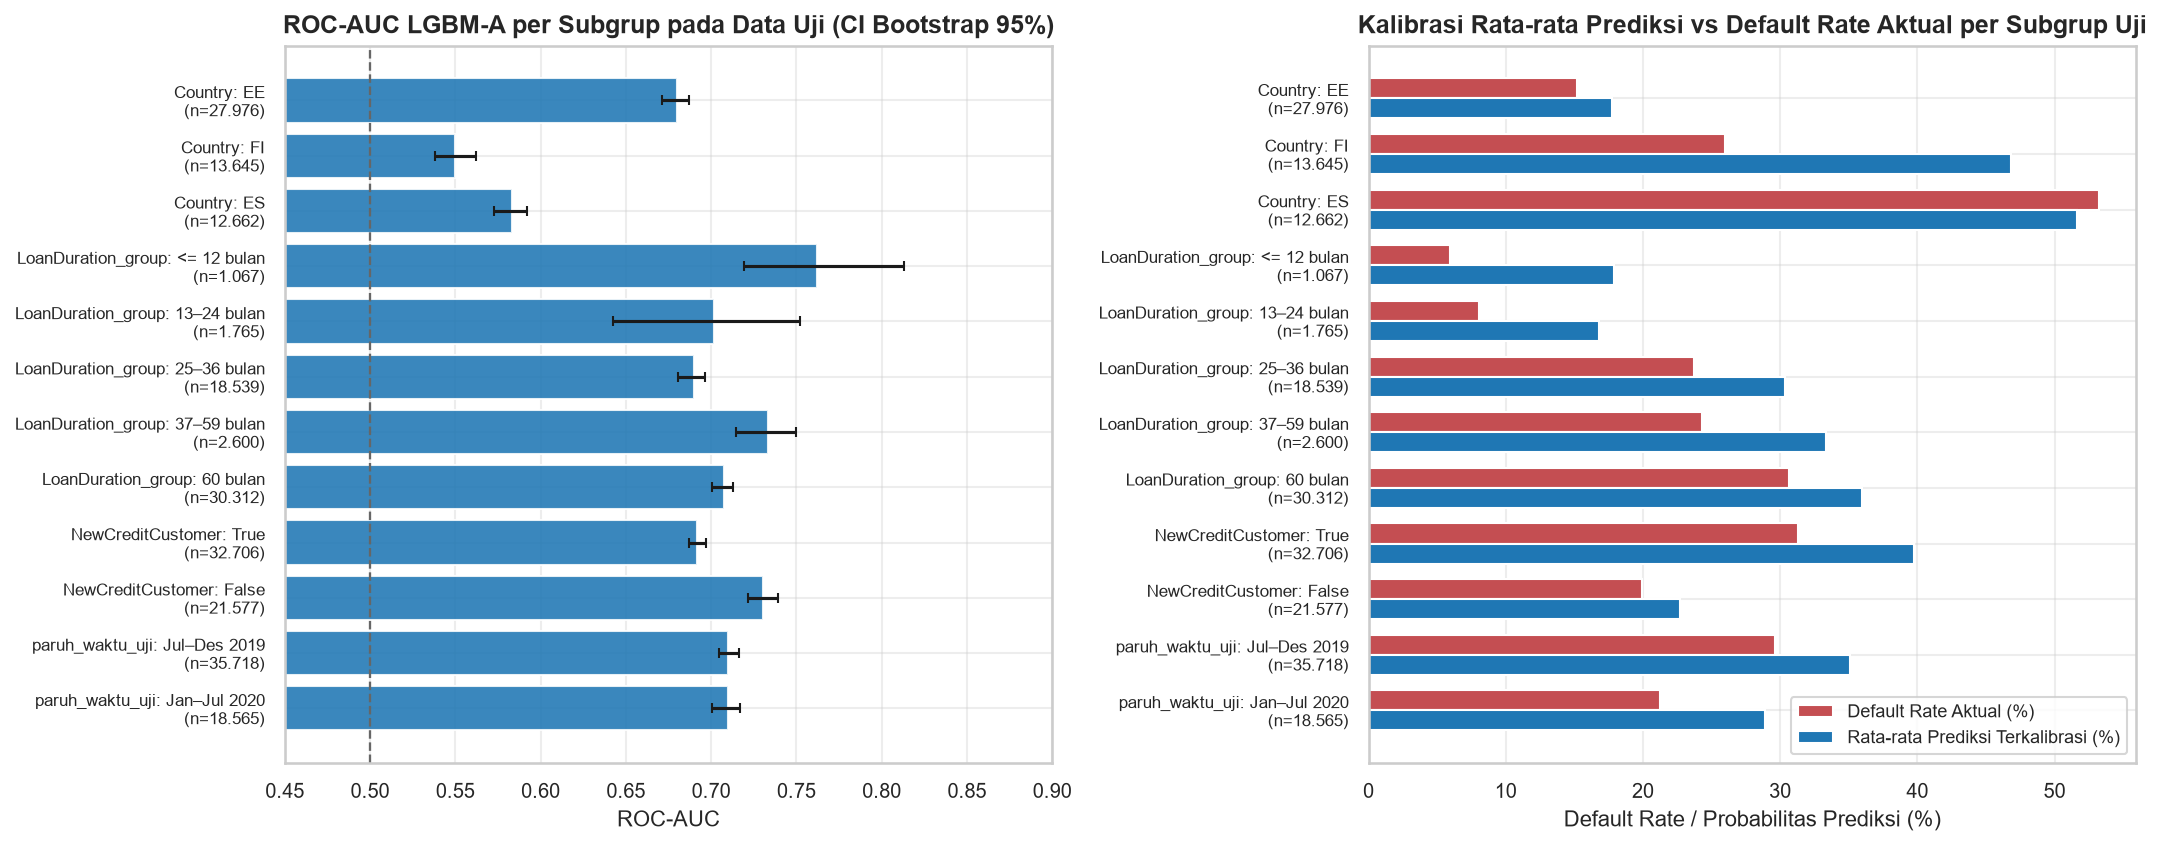

In [5]:
lift_cls_df = pd.read_csv(config.TABLES_DIR / "04_lift_by_decile.csv")
subgrp_df = pd.read_csv(config.TABLES_DIR / "04_subgroup_performance.csv")

print("=== Tabel Lift & Cumulative Gain 10 Desil pada Data Uji (LGBM-A Terkalibrasi) ===")
display(lift_cls_df)

print("\n=== Kinerja Model Utama LGBM-A per Subgrup pada Data Uji ===")
display(subgrp_df)

print("\n=== Pembanding Dalam-Negara pada Baris Uji yang Sama: LGBM-A vs PD Bondora vs Interest ===")
cmp_cols = ["subgrup", "kode_model", "n", "roc_auc", "auc_ci_low_95", "auc_ci_high_95",
            "selisih_auc_lgbm_a_minus_pembanding", "selisih_auc_ci_low_95", "selisih_auc_ci_high_95"]
display(subgrp_df.loc[subgrp_df["dimensi"] == "Country", cmp_cols].reset_index(drop=True))

# Verifikasi: selisih titik = AUC LGBM-A - AUC pembanding, dan CI memuat selisih titik
for c in ["EE", "FI", "ES"]:
    blk = subgrp_df.loc[(subgrp_df["dimensi"] == "Country") & (subgrp_df["subgrup"] == c)].set_index("kode_model")
    for code in ["BASE-PD-Bondora", "BASE-Interest"]:
        d = blk.loc[code]
        assert abs(d["selisih_auc_lgbm_a_minus_pembanding"] - (blk.loc["LGBM-A", "roc_auc"] - d["roc_auc"])) < 2e-6
        sig = "ya" if (d["selisih_auc_ci_low_95"] > 0 or d["selisih_auc_ci_high_95"] < 0) else "TIDAK (CI mencakup 0)"
        print(f"{c} LGBM-A vs {code:16s}: selisih {d['selisih_auc_lgbm_a_minus_pembanding']:+.4f} "
              f"[{d['selisih_auc_ci_low_95']:+.4f}, {d['selisih_auc_ci_high_95']:+.4f}] -> berbeda nyata: {sig}")

display(Image(filename=str(config.FIGURES_DIR / "04_lift_by_decile.png")))
display(Image(filename=str(config.FIGURES_DIR / "04_subgroup_performance.png")))

## 4b. Bias Level Probabilitas: Rata-rata Prediksi vs Default 12 Bulan Aktual (`04_level_bias.csv`)

Rata-rata `p_calibrated` (`LGBM-A`) dibandingkan dengan tingkat gagal bayar 12 bulan aktual:
- **Validasi (in-sample):** `29,26%` vs `29,26%`. Selisih nol di sini **hanya akibat konstruksi** (kalibrator isotonik dipelajari dari data validasi), bukan bukti kalibrasi yang baik.
- **Uji (out-of-sample, angka yang dilaporkan):** rata-rata prediksi **`32,96%` vs aktual `26,77%`** (`+6,19 pp`, rasio `1,23`) — **level probabilitas uji cenderung terlalu tinggi.**
- **Uji menurut `Country`:** `EE` `17,74%` vs `15,16%` (`+2,58 pp`); `FI` `46,82%` vs `25,99%` (**`+20,83 pp`**, rasio `1,80`); `ES` `51,65%` vs `53,27%` (`-1,62 pp`). Over-prediksi terkonsentrasi di Finlandia.
- **Uji menurut paruh waktu:** `Jul–Des 2019` `35,08%` vs `29,64%` (`+5,44 pp`); `Jan–Jul 2020` `28,88%` vs `21,24%` (`+7,63 pp`). Over-prediksi `FI` terjadi di kedua paruh (`+19,65 pp` dan `+23,31 pp`).
- **Pembanding:** rata-rata `ProbabilityOfDefault` Bondora pada uji `22,14%` (`-4,63 pp`, justru terlalu rendah; `-23,23 pp` di `ES`).
- **Kesimpulan:** **urutan risiko lebih andal daripada level.** ROC-AUC stabil lintas paruh waktu (`0,7099` vs `0,7098`), sedangkan selisih level berubah (`+5,44` menjadi `+7,63 pp`) dan sangat berbeda antar-negara. `p_calibrated` sebaiknya dipakai terutama sebagai **urutan**; angka absolutnya perlu diperlakukan hati-hati. Penyebab bias level **belum diuji** (tingkat default latih `31,03%` lebih tinggi daripada uji `26,77%` hanyalah observasi yang konsisten, bukan bukti).

In [6]:
level_df = pd.read_csv(config.TABLES_DIR / "04_level_bias.csv")
display(level_df.drop(columns=["sifat_metrik"]))

row_test = level_df.loc[(level_df["cakupan"] == "Seluruh") & (level_df["split"] == "test")].iloc[0]
row_val = level_df.loc[(level_df["cakupan"] == "Seluruh") & (level_df["split"] == "val")].iloc[0]
print(f"Uji      : rata-rata p_calibrated = {row_test['mean_p_calibrated']:.4%} vs aktual {row_test['default_12m_aktual']:.4%} "
      f"(selisih {row_test['selisih_cal_minus_aktual_pp']:+.2f} pp; rasio {row_test['rasio_cal_per_aktual']:.2f})")
print(f"Validasi : rata-rata p_calibrated = {row_val['mean_p_calibrated']:.4%} vs aktual {row_val['default_12m_aktual']:.4%}  <- in-sample (kalibrator dilatih di sini)")
print("Sifat metrik uji     :", row_test["sifat_metrik"])
print("Sifat metrik validasi:", row_val["sifat_metrik"])
assert abs(row_test["mean_p_calibrated"] - 0.32959) < 5e-5 and abs(row_test["default_12m_aktual"] - 0.267708) < 5e-6

,cakupan,split,subgrup,n,n_default,default_12m_aktual,mean_p_raw,mean_p_calibrated,selisih_cal_minus_aktual_pp,rasio_cal_per_aktual,mean_pd_bondora,selisih_pd_minus_aktual_pp
0,Seluruh,val,Seluruh,34627,10133,0.292633,0.350534,0.292633,0.0000,1.0000,0.278332,-1.4301
1,Seluruh,test,Seluruh,54283,14532,0.267708,0.391292,0.329590,6.1882,1.2312,0.221384,-4.6324
2,Country,test,EE,27976,4241,0.151594,0.226119,0.177397,2.5803,1.1702,0.173278,2.1684
3,Country,test,FI,13645,3546,0.259875,0.538628,0.468171,20.8295,1.8015,0.246702,-1.3173
4,Country,test,ES,12662,6745,0.532696,0.597461,0.516514,-1.6182,0.9696,0.300390,-23.2306
5,paruh_waktu_uji,test,Jul–Des 2019,35718,10588,0.296433,0.414450,0.350809,5.4376,1.1834,0.229186,-6.7247
6,paruh_waktu_uji,test,Jan–Jul 2020,18565,3944,0.212443,0.346737,0.288767,7.6325,1.3593,0.206375,-0.6068
7,Country x paruh_waktu_uji,test,EE | Jul–Des 2019,16813,2814,0.167370,0.228101,0.179837,1.2467,1.0745,0.171295,0.3925
8,Country x paruh_waktu_uji,test,EE | Jan–Jul 2020,11163,1427,0.127833,0.223133,0.173722,4.5889,1.3590,0.176264,4.8431
9,Country x paruh_waktu_uji,test,FI | Jul–Des 2019,9247,2567,0.277604,0.545624,0.474103,19.6500,1.7078,0.256939,-2.0664


Uji      : rata-rata p_calibrated = 32.9590% vs aktual 26.7708% (selisih +6.19 pp; rasio 1.23)
Validasi : rata-rata p_calibrated = 29.2633% vs aktual 29.2633%  <- in-sample (kalibrator dilatih di sini)
Sifat metrik uji     : uji (out-of-sample): metrik yang dipakai untuk pelaporan
Sifat metrik validasi: validasi (in-sample): penyetelan hiperparameter, early stopping, kalibrator, dan ambang Youden dipelajari dari data ini; bukan untuk pelaporan


## 5. Interpretabilitas Model: SHAP, Permutation Importance, Koefisien LR-A, & IV Data Latih (`04_shap_top15.csv`, `04_permutation_importance.csv`, `04_driver_ranking_train_only.csv`)

Untuk memastikan transparansi keputusan kredit:
1. **Global SHAP (`shap.TreeExplainer` pada `5.000` sampel uji) & Permutation Importance (data validasi):** Keduanya secara konsisten menempatkan `Country`, `LanguageCode`, `PreviousRepaymentsBeforeLoan`, `CreditScoreEeMini`, `Age`, `Education`, dan `HomeOwnershipType` sebagai penggerak utama prediksi gagal bayar.
2. **Perbandingan IV Data Latih vs IV Tahap 3:** Menghitung ulang *Information Value* (IV) murni pada data latih (`<= 2018-06-30`) membuktikan bahwa beberapa fitur yang tampak lemah di seluruh populasi Tahap 3 karena telah menjadi konstan pasca-2018 (seperti `CreditScoreEsMicroL` IV latih `0,4261` vs IV Tahap 3 `0,1805`, atau `MaritalStatus` IV latih `0,0700` vs `0,0264`) memang hanya informatif di era lama dan tepat dikeluarkan dari **Set A**.
3. **Penjelasan Lokal (3 Contoh Pinjaman Uji):** Menampilkan dekomposisi *log-odds* SHAP untuk profil pinjaman risiko rendah (`~P10`, `EE`), risiko menengah (`~Median`, `EE`), dan risiko tinggi (`~P90`, `ES`).

=== 15 Fitur Teratas menurut Mean |SHAP| pada Sampel Uji (n = 5.000) ===


,peringkat_shap,fitur,mean_abs_shap,mean_signed_shap,n_sampel_uji,metode
0,1,Country,0.469098,0.115395,5000,shap.TreeExplainer
1,2,LanguageCode,0.245452,0.072995,5000,shap.TreeExplainer
2,3,PreviousRepaymentsBeforeLoan,0.106458,0.029029,5000,shap.TreeExplainer
3,4,ExistingLiabilities,0.093884,0.059124,5000,shap.TreeExplainer
4,5,Education,0.078574,0.017025,5000,shap.TreeExplainer
5,6,CreditScoreEeMini,0.075865,-0.003298,5000,shap.TreeExplainer
6,7,Age,0.073834,-0.011347,5000,shap.TreeExplainer
7,8,HomeOwnershipType,0.072534,0.011358,5000,shap.TreeExplainer
8,9,CreditScoreFiAsiakasTietoRiskGrade,0.070612,0.056628,5000,shap.TreeExplainer
9,10,VerificationType,0.053944,-0.019513,5000,shap.TreeExplainer



=== 15 Fitur Teratas menurut Permutation Importance pada Data Validasi ===


,peringkat_permutation,fitur,auc_drop_mean,auc_drop_std,baseline_val_auc,n_repeats
0,1,Country,0.084052,0.002097,0.744956,5
1,2,LanguageCode,0.016984,0.000796,0.744956,5
2,3,CreditScoreEeMini,0.009738,0.000255,0.744956,5
3,4,Age,0.007324,0.000564,0.744956,5
4,5,PreviousRepaymentsBeforeLoan,0.007286,0.001004,0.744956,5
5,6,HomeOwnershipType,0.007109,0.000457,0.744956,5
6,7,Education,0.005942,0.000226,0.744956,5
7,8,CreditScoreFiAsiakasTietoRiskGrade,0.003852,0.000199,0.744956,5
8,9,AmountOfPreviousLoansBeforeLoan,0.002145,0.000448,0.744956,5
9,10,LoanDuration,0.001910,0.000140,0.744956,5



=== 15 Koefisien Terstandarisasi Terbesar pada Logistic Regression (LR-A) ===


,peringkat,fitur_transformed,koefisien_terstandarisasi,abs_koefisien,arah
0,1,PreviousRepaymentsBeforeLoan_isnan,-0.815351,0.815351,Negatif (- risiko default)
1,2,Country_EE,-0.632791,0.632791,Negatif (- risiko default)
2,3,CreditScoreFiAsiakasTietoRiskGrade_RL1,-0.555837,0.555837,Negatif (- risiko default)
3,4,MonthlyPayment_isnan,-0.498867,0.498867,Negatif (- risiko default)
4,5,monthly_payment_to_income_ratio_isnan,-0.462320,0.462320,Negatif (- risiko default)
5,6,LanguageCode_1,-0.461433,0.461433,Negatif (- risiko default)
6,7,PreviousRepaymentsBeforeLoan,-0.458957,0.458957,Negatif (- risiko default)
7,8,CreditScoreFiAsiakasTietoRiskGrade_RL2,-0.439157,0.439157,Negatif (- risiko default)
8,9,CreditScoreFiAsiakasTietoRiskGrade_5,0.402774,0.402774,Positif (+ risiko default)
9,10,CreditScoreFiAsiakasTietoRiskGrade_4,0.394111,0.394111,Positif (+ risiko default)



=== Perbandingan Peringkat IV Data Latih (<= Jun 2018) vs IV Tahap 3 (Top 20) ===


,peringkat_train_only,peringkat_tahap3,perubahan_peringkat_vs_tahap3,fitur,di_set_A,iv_train_only,iv_tahap3_semua
0,1,1,0,LanguageCode,True,0.6398,0.5428
1,2,2,0,Country,True,0.6312,0.5383
2,3,4,1,CreditScoreEsMicroL,False,0.4261,0.1805
3,4,3,-1,CreditScoreEeMini,True,0.3847,0.4288
4,5,6,1,MonthlyPayment,True,0.1758,0.1219
5,6,9,3,MonthlyPaymentDay,True,0.1574,0.1186
6,7,11,4,PreviousRepaymentsBeforeLoan,True,0.1478,0.0968
7,8,5,-3,NewCreditCustomer,True,0.1342,0.1224
8,9,13,4,monthly_payment_to_income_ratio,True,0.1326,0.0755
9,10,16,6,ExistingLiabilities,True,0.1177,0.0671



=== Contoh Penjelasan Lokal SHAP untuk 3 Pinjaman Uji (Rendah ~P10, Median ~P50, Tinggi ~P90) ===


,profil_pinjaman,LoanId,Country,Rating,default_12m_aktual,p_calibrated,PD_bondora,base_value_log_odds,peringkat_kontribusi,fitur,nilai_fitur,shap_log_odds,arah_risiko
0,Risiko Rendah (~P10),BEE7527E-F235-4063-9DE3-AA7D00D64E5C,EE,E,0,0.1028,0.3280,-0.9217,1,Country,EE,-0.3893,Menurunkan risiko (-)
1,Risiko Rendah (~P10),BEE7527E-F235-4063-9DE3-AA7D00D64E5C,EE,E,0,0.1028,0.3280,-0.9217,2,LanguageCode,1,-0.2319,Menurunkan risiko (-)
2,Risiko Rendah (~P10),BEE7527E-F235-4063-9DE3-AA7D00D64E5C,EE,E,0,0.1028,0.3280,-0.9217,3,Education,1,0.1207,Meningkatkan risiko (+)
3,Risiko Rendah (~P10),BEE7527E-F235-4063-9DE3-AA7D00D64E5C,EE,E,0,0.1028,0.3280,-0.9217,4,CreditScoreEeMini,1000.0,-0.1179,Menurunkan risiko (-)
4,Risiko Rendah (~P10),BEE7527E-F235-4063-9DE3-AA7D00D64E5C,EE,E,0,0.1028,0.3280,-0.9217,5,ExistingLiabilities,1,0.0883,Meningkatkan risiko (+)
5,Risiko Rendah (~P10),BEE7527E-F235-4063-9DE3-AA7D00D64E5C,EE,E,0,0.1028,0.3280,-0.9217,6,VerificationType,4,-0.0765,Menurunkan risiko (-)
6,Risiko Rendah (~P10),BEE7527E-F235-4063-9DE3-AA7D00D64E5C,EE,E,0,0.1028,0.3280,-0.9217,7,EmploymentDurationCurrentEmployer,MoreThan5Years,-0.0465,Menurunkan risiko (-)
7,Risiko Rendah (~P10),BEE7527E-F235-4063-9DE3-AA7D00D64E5C,EE,E,0,0.1028,0.3280,-0.9217,8,HomeOwnershipType,1,-0.0362,Menurunkan risiko (-)
8,Risiko Menengah (~Median),87E162F6-4338-4DD8-837E-AA7D004A5014,EE,D,0,0.2939,0.2273,-0.9217,1,Age,22,0.4656,Meningkatkan risiko (+)
9,Risiko Menengah (~Median),87E162F6-4338-4DD8-837E-AA7D004A5014,EE,D,0,0.2939,0.2273,-0.9217,2,Country,EE,-0.3556,Menurunkan risiko (-)


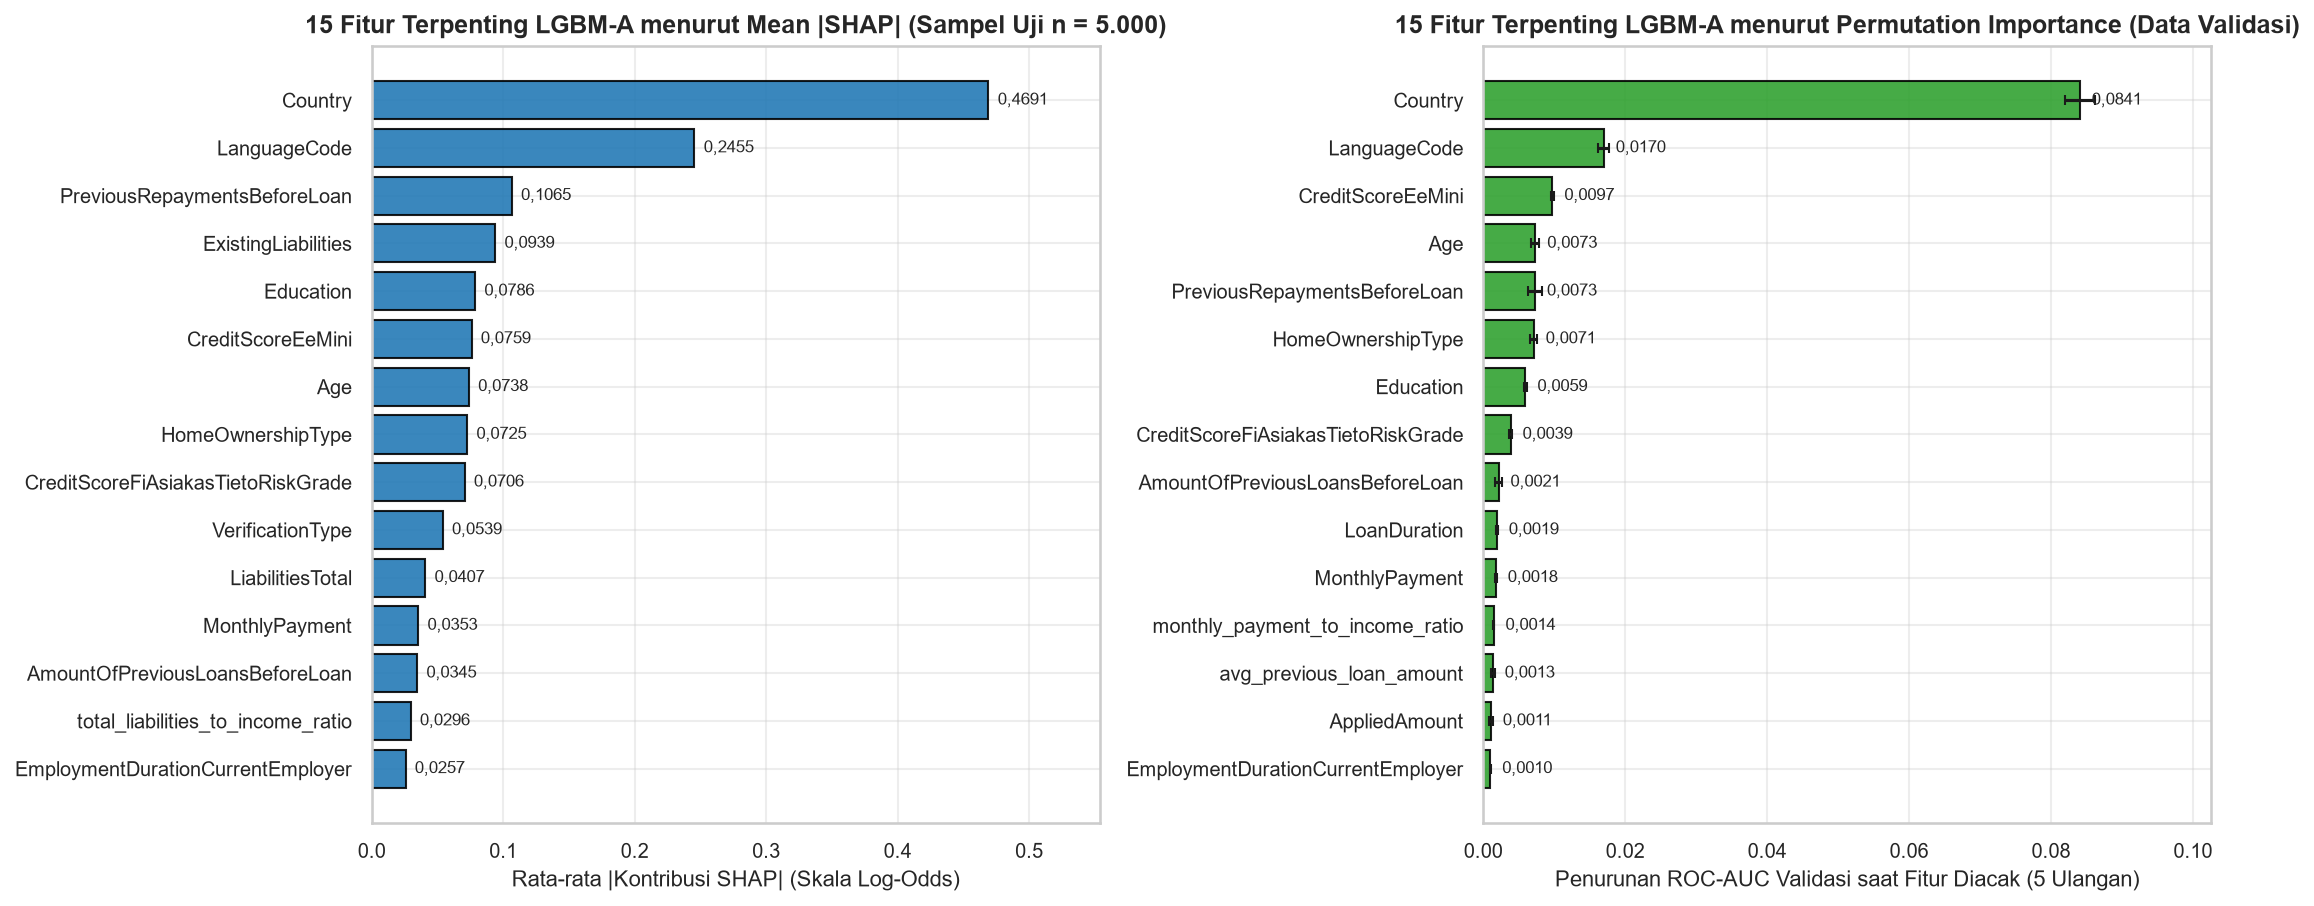

In [7]:
shap_top15_df = pd.read_csv(config.TABLES_DIR / "04_shap_top15.csv")
perm_df = pd.read_csv(config.TABLES_DIR / "04_permutation_importance.csv")
lr_coef_df = pd.read_csv(config.TABLES_DIR / "04_lr_top15_coefficients.csv")
iv_train_df = pd.read_csv(config.TABLES_DIR / "04_driver_ranking_train_only.csv")
local_ex_df = pd.read_csv(config.TABLES_DIR / "04_local_explanations_examples.csv")

print("=== 15 Fitur Teratas menurut Mean |SHAP| pada Sampel Uji (n = 5.000) ===")
display(shap_top15_df)

print("\n=== 15 Fitur Teratas menurut Permutation Importance pada Data Validasi ===")
display(perm_df.head(15))

print("\n=== 15 Koefisien Terstandarisasi Terbesar pada Logistic Regression (LR-A) ===")
display(lr_coef_df)

print("\n=== Perbandingan Peringkat IV Data Latih (<= Jun 2018) vs IV Tahap 3 (Top 20) ===")
display(iv_train_df.head(20))

print("\n=== Contoh Penjelasan Lokal SHAP untuk 3 Pinjaman Uji (Rendah ~P10, Median ~P50, Tinggi ~P90) ===")
display(local_ex_df)

display(Image(filename=str(config.FIGURES_DIR / "04_shap_summary_bar.png")))

## 5b. Pemeriksaan `NaN` sebagai Sinyal Era (`04_nan_signal_shap.csv`, `04_nan_signal_refit.csv`)

Walaupun kolom indikator eksplisit `*_missing` telah dikeluarkan (`boleh_jadi_fitur = N`) dan 8 fitur *mati-era* telah disaring dari **Set A**, algoritma pohon seperti LightGBM secara bawaan mempelajari arah cabang khusus untuk nilai `NaN` (*default direction for missing values*). Untuk menguji apakah model utama `LGBM-A` diam-diam mengandalkan keberadaan `NaN` sebagai sinyal era:

1. **Perbandingan Rata-rata SHAP Baris `NaN` vs Non-`NaN` (`04_nan_signal_shap.csv`):**
   - Lima fitur di dalam **Set A** memiliki proporsi `NaN` yang terkonsentrasi pada era tertentu (`max NaN >= 1%` dan rentang antar-split `>= 5 pp`): `PreviousRepaymentsBeforeLoan`, `MonthlyPayment`, `monthly_payment_to_income_ratio`, `CreditScoreFiAsiakasTietoRiskGrade`, dan `CreditScoreEeMini`.
   - **`PreviousRepaymentsBeforeLoan`** (`NaN`: latih `4,94%`, val `8,25%`, uji `1,85%`): pada sampel SHAP uji (`n = 5.000`, `88` baris `NaN`), rata-rata SHAP baris `NaN` adalah **`-0,2103`** vs non-`NaN` **`+0,0333`** (`selisih = -0,2436` *log-odds*; default rate aktual pada baris `NaN` uji `10,23%` vs non-`NaN` `26,40%`).
   - **`MonthlyPayment`** (`NaN`: latih `11,25%`, val `0,00%`, uji `0,00%`) dan **`monthly_payment_to_income_ratio`** (`NaN`: latih `11,27%`, val `0,00%`, uji `0,00%`): karena tidak ada `NaN` pada periode uji (`n_nan = 0`), perbandingan dihitung pula pada sampel acak data latih (`n = 5.000`). Pada sampel latih, baris `NaN` `MonthlyPayment` memiliki rata-rata SHAP **`-0,3185`** vs non-`NaN` **`+0,0367`** (`selisih = -0,3552`), dan baris `NaN` `monthly_payment_to_income_ratio` memiliki rata-rata SHAP **`-0,1460`** vs non-`NaN` **`+0,0144`** (`selisih = -0,1604`).
   - **`CreditScoreEeMini`** (`NaN`: latih `47,36%`, val `38,29%`, uji `48,47%`): pada sampel SHAP uji, rata-rata SHAP baris `NaN` adalah **`+0,0166`** vs non-`NaN` **`-0,0222`** (`selisih = +0,0388`).
   - **`CreditScoreFiAsiakasTietoRiskGrade`** (`NaN`: latih `82,47%`, val `66,99%`, uji `74,85%`): pada sampel SHAP uji, rata-rata SHAP baris `NaN` adalah **`+0,0523`** vs non-`NaN` **`+0,0691`** (`selisih = -0,0169`).
2. **Eksperimen Latih Ulang Satu Kali dengan `NaN` Diisi Nilai Konstan Tunggal (`04_nan_signal_refit.csv`):**
   - Model `LGBM-A` dilatih ulang **satu kali** menggunakan hiperparameter terbaik yang persis sama (tanpa penyetelan ulang) setelah nilai `NaN` pada kelima fitur tersebut diisi dengan satu nilai konstan dari data latih (`MonthlyPayment = 80,03`, `monthly_payment_to_income_ratio = 0,0640238`, `PreviousRepaymentsBeforeLoan = 0,0`, `CreditScoreEeMini = 1000,0`, `CreditScoreFiAsiakasTietoRiskGrade = 'RL2'`).
   - Hasil pada data uji (`n = 54.283`): ROC-AUC terkalibrasi mencapai **`0,7164`** `[0,7117, 0,7209]` (skor mentah `0,7170` `[0,7122, 0,7215]`, Brier `0,1790`), dibandingkan model utama `LGBM-A` tersimpan **`0,7152`** `[0,7107, 0,7196]` — **selisih `+0,0012` poin AUC** (`CI 95% [+0,0005, +0,0019]`).
   - **Kesimpulan:** Menghilangkan sinyal `NaN` dengan imputasi konstan tunggal sama sekali tidak menurunkan kinerja uji (bahkan sedikit lebih tinggi `+0,0012` AUC), membuktikan bahwa daya pisah `LGBM-A` pada data uji tidak bergantung pada kebocoran sinyal `NaN` antar-era. Sesuai protokol evaluasi, **model utama `LGBM-A` tidak diganti** dan eksperimen ini hanya dilaporkan sebagai bukti ketahanan.

In [8]:
nan_shap_df = pd.read_csv(config.TABLES_DIR / "04_nan_signal_shap.csv")
nan_refit_df = pd.read_csv(config.TABLES_DIR / "04_nan_signal_refit.csv")

print("=== Perbandingan Rata-rata SHAP Baris NaN vs Non-NaN untuk Fitur dengan NaN Terkonsentrasi per Era ===")
display(nan_shap_df.loc[nan_shap_df["fitur"].isin([
    "PreviousRepaymentsBeforeLoan",
    "MonthlyPayment",
    "monthly_payment_to_income_ratio",
    "CreditScoreEeMini",
    "CreditScoreFiAsiakasTietoRiskGrade",
])].reset_index(drop=True))

print("\n=== Hasil Eksperimen Latih Ulang Satu Kali (NaN Diisi Nilai Konstan Tunggal Data Latih vs Model Utama LGBM-A) ===")
display(nan_refit_df)

=== Perbandingan Rata-rata SHAP Baris NaN vs Non-NaN untuk Fitur dengan NaN Terkonsentrasi per Era ===


,fitur,sampel,dipilih_untuk_isian_konstan,n_sampel,n_nan,share_nan,mean_shap_nan,mean_shap_non_nan,selisih_shap_nan_minus_non_nan,mean_abs_shap_nan,mean_abs_shap_non_nan,default_rate_nan,default_rate_non_nan,nan_share_latih,nan_share_validasi,nan_share_uji,rentang_nan_pp,memenuhi_aturan_konsentrasi,dipaksa_masuk_permintaan
0,MonthlyPayment,"uji (sampel SHAP n=5.000, seed sama dengan 04_...",True,5000,0,0.0000,NaN,0.021100,NaN,NaN,0.035310,NaN,0.261200,0.112515,0.000000,0.000000,11.2515,True,True
1,CreditScoreFiAsiakasTietoRiskGrade,"uji (sampel SHAP n=5.000, seed sama dengan 04_...",True,5000,3714,0.7428,0.052297,0.069136,-0.016839,0.052297,0.123507,0.267367,0.243390,0.824669,0.669911,0.748540,15.4758,True,False
2,CreditScoreEeMini,"uji (sampel SHAP n=5.000, seed sama dengan 04_...",True,5000,2435,0.4870,0.016613,-0.022201,0.038815,0.016800,0.131936,0.379877,0.148538,0.473604,0.382909,0.484664,10.1754,True,False
3,PreviousRepaymentsBeforeLoan,"uji (sampel SHAP n=5.000, seed sama dengan 04_...",True,5000,88,0.0176,-0.210318,0.033317,-0.243635,0.210318,0.104597,0.102273,0.264047,0.049446,0.082508,0.018477,6.4031,True,True
4,monthly_payment_to_income_ratio,"uji (sampel SHAP n=5.000, seed sama dengan 04_...",True,5000,0,0.0000,NaN,0.005029,NaN,NaN,0.022179,NaN,0.261200,0.112666,0.000000,0.000000,11.2666,True,False
5,MonthlyPayment,latih (sampel acak n=5.000),True,5000,584,0.1168,-0.318476,0.036707,-0.355183,0.318476,0.046376,0.148973,0.336051,0.112515,0.000000,0.000000,11.2515,True,True
6,CreditScoreFiAsiakasTietoRiskGrade,latih (sampel acak n=5.000),True,5000,4091,0.8182,0.045471,-0.108008,0.153479,0.045471,0.196459,0.295282,0.399340,0.824669,0.669911,0.748540,15.4758,True,False
7,CreditScoreEeMini,latih (sampel acak n=5.000),True,5000,2401,0.4802,0.003919,-0.017276,0.021195,0.017096,0.138060,0.448147,0.190458,0.473604,0.382909,0.484664,10.1754,True,False
8,PreviousRepaymentsBeforeLoan,latih (sampel acak n=5.000),True,5000,251,0.0502,-0.170462,0.000446,-0.170908,0.170462,0.122952,0.227092,0.318804,0.049446,0.082508,0.018477,6.4031,True,True
9,monthly_payment_to_income_ratio,latih (sampel acak n=5.000),True,5000,584,0.1168,-0.145968,0.014372,-0.160340,0.145968,0.029072,0.148973,0.336051,0.112666,0.000000,0.000000,11.2666,True,False



=== Hasil Eksperimen Latih Ulang Satu Kali (NaN Diisi Nilai Konstan Tunggal Data Latih vs Model Utama LGBM-A) ===


,varian,best_iteration,test_auc_raw,test_auc_raw_ci_low_95,test_auc_raw_ci_high_95,metode_kalibrasi,test_auc_calibrated,test_auc_calibrated_ci_low_95,test_auc_calibrated_ci_high_95,selisih_auc_vs_lgbm_a_utama,test_brier_calibrated,test_ece_calibrated,fitur_diisi,konstanta_pengisi,val_auc_raw,selisih_ci_low_95,selisih_ci_high_95,selisih_auc_vs_kontrol_refit
0,"LGBM-A utama (tersimpan, NaN apa adanya)",74,0.715445,0.711028,0.719901,isotonic,0.715155,0.710692,0.719608,0.000000,0.17983,0.061882,-,-,NaN,NaN,NaN,NaN
1,"Kontrol refit (NaN apa adanya, parameter sama)",74,0.715445,0.711028,0.719901,isotonic,0.715155,0.710692,0.719608,0.000000,0.17983,0.061882,-,-,0.744956,0.000000,0.000000,NaN
2,Refit NaN diisi konstanta tunggal (median / mo...,74,0.716975,0.712225,0.721539,isotonic,0.716361,0.711721,0.720924,0.001206,0.17899,0.057681,"MonthlyPayment, CreditScoreFiAsiakasTietoRiskG...",MonthlyPayment=80.03; CreditScoreFiAsiakasTiet...,0.744177,0.000456,0.001919,0.001206


## 6. Verifikasi Tabel Prediksi Klasifikasi (`data/processed/predictions_default12m.parquet`)

Seluruh `148.369` pinjaman pada populasi valid `default_12m` disimpan beserta kolom `split`, konteks pinjaman, `p_raw`, `p_calibrated` (`LGBM-A`), `p_lr` (`LR-A`), dan `PD_bondora` untuk digunakan langsung pada optimasi portofolio di **Tahap 5** dan simulasi kebijakan di **Tahap 7**.

In [9]:
pred_cls_df = pd.read_parquet(config.DATA_PROCESSED / "predictions_default12m.parquet")
print(f"Shape predictions_default12m.parquet : {pred_cls_df.shape}")
print(f"LoanId unik                          : {pred_cls_df['LoanId'].is_unique}")
print(f"Rentang p_raw                        : [{pred_cls_df['p_raw'].min():.4f}, {pred_cls_df['p_raw'].max():.4f}]")
print(f"Rentang p_calibrated                 : [{pred_cls_df['p_calibrated'].min():.4f}, {pred_cls_df['p_calibrated'].max():.4f}]")
print(f"Rentang p_lr                         : [{pred_cls_df['p_lr'].min():.4f}, {pred_cls_df['p_lr'].max():.4f}]")

summary_pred_by_split = pred_cls_df.groupby("split", as_index=False).agg(
    n=("LoanId", "count"),
    default_rate_aktual=("default_12m", "mean"),
    mean_p_raw=("p_raw", "mean"),
    mean_p_calibrated=("p_calibrated", "mean"),
    mean_p_lr=("p_lr", "mean"),
    mean_PD_bondora=("PD_bondora", "mean"),
)
display(summary_pred_by_split)
display(pred_cls_df.head(5))

Shape predictions_default12m.parquet : (148369, 15)
LoanId unik                          : True
Rentang p_raw                        : [0.0734, 0.8248]
Rentang p_calibrated                 : [0.0000, 0.8000]
Rentang p_lr                         : [0.0000, 1.0000]


,split,n,default_rate_aktual,mean_p_raw,mean_p_calibrated,mean_p_lr,mean_PD_bondora
0,test,54283,0.267708,0.391292,0.329590,0.321920,0.221384
1,train,59459,0.310331,0.310477,0.251031,0.246774,0.256090
2,val,34627,0.292633,0.350534,0.292633,0.292633,0.278332


,LoanId,split,LoanDate,loan_year,Country,Rating,Amount,AppliedAmount,Interest,LoanDuration,default_12m,p_raw,p_calibrated,p_lr,PD_bondora
0,66AE108B-532B-4BB3-BAB7-0019A46412C1,train,2016-03-23,2016,EE,C,2125.0,2125.0,20.97,60,0,0.135401,0.057971,0.052239,0.122216
1,D152382E-A50D-46ED-8FF2-0053E0C86A70,train,2015-06-25,2015,EE,B,3000.0,3000.0,17.12,60,1,0.123598,0.033771,0.052239,0.036449
2,87342E13-66CB-483F-833A-007953E50C78,train,2016-01-19,2016,EE,A,9100.0,10630.0,13.67,60,0,0.137992,0.057971,0.092616,0.041344
3,87227056-6BF9-410C-98D1-008F788E122A,train,2015-03-27,2015,ES,F,1500.0,1500.0,40.40,60,1,0.635963,0.535852,0.541313,0.188726
4,2DDE6336-E466-4624-A337-00A0ED1A1468,train,2015-12-22,2015,ES,HR,1090.0,1595.0,68.39,48,1,0.631527,0.535852,0.541313,0.749511


## 7. Ringkasan Temuan Predictive & Implikasi untuk Tahap 5

### Ringkasan Temuan Predictive (12 Butir Utama)
1. **Keunggulan Model Utama atas Benchmark Internal Bondora (`04_metrics_classification.csv`, `04_auc_comparisons.csv`):** Pada data uji temporal (`LoanDate >= 2019-07-01`, `n = 54.283`, default rate `26,77%`), model utama **LGBM-A terkalibrasi (`Set A`, 36 fitur)** mencapai **ROC-AUC `0,7152`** `[0,7107, 0,7196]`, **KS `0,3230`**, **PR-AUC `0,4393`** (`0,4468` sebelum kalibrasi), dan **Brier `0,1798`**. Angka ini mengungguli `ProbabilityOfDefault` Bondora pada baris uji yang sama (**ROC-AUC `0,6746`** `[0,6699, 0,6800]`, KS `0,2718`, Brier `0,1868`; selisih berpasangan **`+0,0406` poin AUC**, CI 95% `[+0,0343, +0,0461]`) maupun pada seluruh populasi teramati Tahap 3 (`0,6998`), serta mengungguli peringkat suku bunga `Interest` (**ROC-AUC `0,6851`**; selisih **`+0,0301` poin AUC**).
2. **Keunggulan Non-Linear GBDT atas Model Linear (`04_metrics_classification.csv`):** Model `LGBM-A` meningkatkan ROC-AUC uji sebesar **`+0,0188` poin** (`0,7152` vs `0,6964`, CI 95% `[+0,0172, +0,0204]`) dan PR-AUC sebesar `+0,0391` poin dibanding regresi logistik terstandarisasi (`LR-A`), membuktikan adanya interaksi non-linear penting antara lokasi geografis, skor biro kredit lokal, dan riwayat pembayaran peminjam.
3. **Deteksi Terprogram 8 Fitur Mati-Era & Pemeriksaan Sinyal `NaN` (`04_feature_sets.csv`, `04_nan_signal_shap.csv`, `04_nan_signal_refit.csv`):** Aturan objektif (`share_dominan_validasi >= 95%` dan `share_dominan_latih <= 80%`) mendeteksi 8 fitur yang berhenti dikumpulkan atau kolaps pasca-2018 (`UseOfLoan`, `MaritalStatus`, `EmploymentStatus`, `OccupationArea`, `IncomeFromPrincipalEmployer`, `DebtToIncome`, `FreeCash`, `CreditScoreEsMicroL`, PSI 2018–2020 `8,27–17,69`). Pemeriksaan SHAP pada 5 fitur Set A yang masih memiliki `NaN` terkonsentrasi per era (`PreviousRepaymentsBeforeLoan` SHAP uji `NaN` `-0,2103` vs non-`NaN` `+0,0333`; `MonthlyPayment` SHAP latih `NaN` `-0,3185` vs non-`NaN` `+0,0367`) serta eksperimen latih ulang satu kali dengan `NaN` diisi konstan tunggal menghasilkan ROC-AUC uji **`0,7164`** (selisih **`+0,0012`** terhadap model utama `0,7152`, CI 95% `[+0,0005, +0,0019]`), membuktikan bahwa kinerja uji `LGBM-A` tidak bertumpu pada kebocoran sinyal `NaN`.
4. **Temuan Ablasi Set C (`04_metrics_classification.csv`, `04_auc_comparisons.csv`):** Menambahkan `Rating`, `ProbabilityOfDefault`, dan `Interest` ke dalam `Set A` (`LGBM-C`, 39 fitur) menghasilkan ROC-AUC validasi `0,7470` (vs `0,7460` pada `LGBM-A`) dan ROC-AUC uji `0,7078` (vs `0,7152` pada `LGBM-A`, CI 95% selisih `[-0,0093, -0,0055]`): **tidak menambah AUC; penurunan di uji (-0,0074) kecil dan penyebabnya belum dibuktikan**.
5. **Bukti Empiris Optimisme Semu pada Split Acak (`04_metrics_classification.csv`, `04_split_summary.csv`):** Ketika dievaluasi dengan pembagian acak terstratifikasi `70/15/15` (`LGBM-A-acak`, `n_test = 22.256`), ROC-AUC uji melonjak ke **`0,7879`** `[0,7813, 0,7942]` dan PR-AUC ke **`0,6045`** — menciptakan **optimisme semu sebesar `+0,0728` poin AUC (`+7,28` poin persentase)** dibanding evaluasi berbasis waktu (`0,7152`). Ini terjadi karena split acak mengizinkan pohon keputusan mempelajari karakteristik kohort masa depan yang tercampur di dalam data latih pada periode waktu yang sama.
6. **Kalibrasi Probabilitas, Cakupan Metrik In-Sample vs Out-of-Sample, & Bias Level Uji (`04_calibration_curve.png`, `04_level_bias.csv`):** Metrik kalibrasi pada data validasi (`val`, rata-rata prediksi `29,26%` = aktual `29,26%`, ECE `0,0000`) **bersifat *in-sample*** karena kalibrator isotonik dipelajari pada data validasi yang sama; **hanya metrik data uji (*out-of-sample*) yang dipakai untuk pelaporan**. Pada data uji (`n = 54.283`), kalibrasi isotonik memperbaiki Brier dari `0,1926` menjadi **`0,1798`** dan menurunkan ECE dari `0,1236` menjadi **`0,0619`**, namun **level probabilitas uji masih cenderung terlalu tinggi (rata-rata prediksi `32,96%` vs aktual `26,77%`, selisih `+6,19 pp`)**, terutama akibat *over-prediction* di Finlandia (`46,82%` vs aktual `25,99%`, `+20,83 pp`) dan konsisten di kedua paruh waktu uji (`Jul–Des 2019`: `35,08%` vs `29,64%`; `Jan–Jul 2020`: `28,88%` vs `21,24%`). Oleh sebab itu, **urutan risiko lebih andal daripada level probabilitas absolut**.
7. **Daya Tangkap Risiko (*Decile Lift*) untuk Penyaringan Kredit (`04_lift_by_decile.csv`):** Sepuluh persen pinjaman berisiko tertinggi (**Desil 1**, `p_calibrated >= 0,5517`) memiliki tingkat gagal bayar aktual **`53,80%`** (**lift `2,01x`**), sedangkan **Desil 10** (`p_calibrated <= 0,1028`) hanya mengalami gagal bayar **`5,18%`** (**lift `0,19x`**). Menolak 20% pengajuan berisiko tertinggi sudah mengeliminasi **`35,88%`** (`5.214` dari `14.532`) kejadian gagal bayar 12 bulan.
8. **Disparitas Kinerja Subgrup & Pembanding Dalam-Negara (`04_subgroup_performance.csv`):** Pada baris uji yang sama, perbandingan ROC-AUC dalam-negara `LGBM-A` vs `ProbabilityOfDefault` Bondora vs `Interest` menunjukkan: di **Estonia (`EE`, `n = 27.976`)** `LGBM-A` `0,6799` unggul signifikan atas PD `0,6295` (**`+0,0504`** `[+0,0397, +0,0608]`) dan `Interest` `0,6034` (**`+0,0765`** `[+0,0658, +0,0859]`); di **Spanyol (`ES`, `n = 12.662`)** `LGBM-A` `0,5831` unggul signifikan atas PD `0,5556` (**`+0,0275`** `[+0,0169, +0,0395]`) dan `Interest` `0,5522` (**`+0,0309`** `[+0,0202, +0,0431]`); sedangkan di **Finlandia (`FI`, `n = 13.645`)** `LGBM-A` `0,5496` unggul atas `Interest` `0,5051` (**`+0,0446`** `[+0,0291, +0,0617]`) namun **tidak berbeda nyata dari PD `0,5560`** (selisih **`-0,0063`** `[-0,0211, +0,0090]`, CI mencakup 0). Lintas kelompok tenor (`LoanDuration_group`), model mempertahankan ROC-AUC stabil antara `0,6897` (`25–36 bulan`) hingga `0,7622` (`<= 12 bulan`), serta lebih akurat pada peminjam lama (`NewCreditCustomer == False`, AUC `0,7302`) dibanding peminjam baru (`True`, AUC `0,6920`).
9. **Konsistensi Penggerak Utama Risiko: SHAP vs Permutation vs IV Latih (`04_shap_top15.csv`, `04_permutation_importance.csv`, `04_driver_ranking_train_only.csv`):** Lima fitur teratas menurut `Mean |SHAP|` pada sampel uji (`Country` `0,4691`, `LanguageCode` `0,2455`, `PreviousRepaymentsBeforeLoan` `0,1065`, `ExistingLiabilities` `0,0939`, `Education` `0,0786`) selaras dengan *Permutation Importance* pada validasi (`Country` menurunkan AUC `0,0841`, `LanguageCode` `0,0170`, `CreditScoreEeMini` `0,0097`, `Age` `0,0073`, `PreviousRepaymentsBeforeLoan` `0,0073`). Perbandingan IV khusus data latih mengonfirmasi bahwa `Age` (peringkat 32 di IV univariat latih, namun peringkat 4 di *Permutation Importance* dan peringkat 7 di SHAP) memiliki kontribusi interaksi multivariat yang kuat bersama negara dan durasi kerja.
10. **Kinerja Regresi `return_ratio`, Bias Level, & Kegunaan sebagai Urutan (`05_metrics_regression.csv`, `05_lift_by_decile.csv`):** Pada populasi `is_resolved == True` (`n_test = 34.675`), model utama **LGBM-Reg-Huber (`Set A`)** mencapai **MAE `0,3902`**, **RMSE `0,4545`**, **$R^2 = 0,0252`**, dan **Spearman $ho_s = 0,2881$** (mengalahkan baseline median `Country × Rating` dengan MAE `0,4697`, $R^2 = -0,4868$, serta `ExpectedReturn` Bondora yang berkorelasi terbalik $ho_s = -0,1651$). Sejalan dengan klasifikasi, **level prediksi regresi pada uji cenderung terlalu tinggi (rata-rata prediksi `0,6746` vs aktual `0,5708`, selisih `+0,1038`)**, sehingga **prediksi regresi harus digunakan sebagai urutan (*ranking*), bukan angka pengembalian absolut** — di mana urutan peringkatnya efektif memisahkan **Desil 1 tertinggi** (mean aktual **`0,9014`**, median `1,0405`, lift **`1,58x`**) dari **Desil 10 terendah** (mean aktual **`0,4168`**, median `0,2355`, selisih **`+0,4846`**).
11. **Penggerak Utama Regresi `return_ratio` (`05_shap_top15.csv`):** Kontribusi SHAP regresi didominasi oleh `LanguageCode` (`0,0907`), `Country` (`0,0726`), `PreviousRepaymentsBeforeLoan` (`0,0468`), `AmountOfPreviousLoansBeforeLoan` (`0,0465`), dan `total_liabilities_to_income_ratio` (`0,0359`). Ini menegaskan bahwa riwayat pembayaran masa lalu dan beban kewajiban terhadap pendapatan tidak hanya menentukan peluang gagal bayar 12 bulan, tetapi juga tingkat pemulihan kas (*cash recovery*) ketika pinjaman bermasalah.
12. **Keterbatasan Utama yang Wajib Diperhitungkan:** (a) **Bias seleksi populasi *resolved*** pada regresi: kohort uji `>= Juli 2019` yang sudah berstatus *resolved* per `2021-07-20` didominasi oleh gagal bayar dini (`64,49%` default) atau pelunasan dipercepat, sehingga menekan rata-rata `return_ratio` aktual dari `0,9136` (latih) menjadi `0,5708` (uji); (b) **Bias level lintas waktu dan negara** pada probabilitas klasifikasi (`32,96%` vs `26,77%`, terutama di `FI` `+20,83 pp`) maupun regresi (`0,6746` vs `0,5708`); serta (c) **Dominasi variabel geografis (`Country`/`LanguageCode`)** yang menuntut kendala diversifikasi negara pada optimasi portofolio agar alokasi tidak terkonsentrasi tunggal di Estonia.

---

### Implikasi untuk Tahap 5 (Prescriptive Analytics & Optimasi Portofolio)
1. **Model & Probabilitas yang Dipakai untuk Optimasi:** Gunakan **`LGBM-A` terkalibrasi isotonik (`p_calibrated` dari `predictions_default12m.parquet`)** sebagai estimasi risiko gagal bayar 12 bulan ($\hat{p}_i$) karena terbukti paling unggul di data uji (`AUC 0,7152`, `Brier 0,1798`), bebas dari fitur *mati-era*, dan tidak bergantung pada kebocoran sinyal `NaN`.
2. **Peran Prediksi Regresi (`pred_return_ratio`):** Karena rata-rata prediksi regresi pada data uji lebih tinggi daripada rata-rata aktual (`0,6746` vs `0,5708`) dan $R^2$ absolut rendah (`0,0252`) akibat penyensoran waktu pengamatan kohort *resolved*, **gunakan `pred_return_ratio` sebagai urutan (*ranking*)** pendamping, sedangkan ekspektasi imbal hasil dalam optimasi dihitung secara struktural dari suku bunga, probabilitas gagal bayar, dan asumsi tingkat pemulihan.
3. **Tingkat Kepercayaan Urutan Risiko vs Level Absolut:** Urutan risiko (*ranking* / *decile lift*) sangat stabil lintas paruh waktu uji (`Jul–Des 2019` AUC `0,7099` vs `Jan–Jul 2020` AUC `0,7098`), sementara level probabilitas uji rata-rata lebih tinggi `+6,19 pp` (`32,96%` vs `26,77%`). Oleh sebab itu, batasan anggaran risiko (*risk budget constraint*) pada pemrograman linier `PuLP` di Tahap 5 wajib dilengkapi **analisis sensitivitas ambang batas risiko**, **kalibrasi ulang/penyesuaian skala skenario**, serta **batas konsentrasi maksimum per negara (`Country`)**.